---
title: "Temporal internal evaluation of first readmission, 2021-2024"
description: |
  Additional within-SENDA evaluation of the development-only pipeline.
  The historical cohort rules and December 20, 2024 readmission cutoff are
  reproduced before applying the five frozen imputers and the models from 09.
  The approved dissociative category maps to other substances. The poverty
  definition used in development is retained by the recorded final decision.
date: last-modified
author: "Andr\u00e9s-Gonz\u00e1lez Santa Cruz"
toc: true
toc-location: left
number-sections: true
format:
  html:
    css: ["_lib/styles.scss", "_lib/prediction_metrics_compact.css"]
    code-fold: true
    code-tools: true
    embed-resources: true
    fig-cap-location: top
    theme: journal
execute:
  error: false
  echo: true
  warning: true
  message: true
  cache: false
  freeze: false
jupyter: ir
editor: source
---

# Scope and execution boundary
The primary temporal score is net first-readmission risk. Observed follow-up has administrative censoring at December 20, 2024; individual post-2020 death ascertainment is unavailable. Death dates are therefore neither fabricated nor used to censor observed temporal outcomes. CIF predictions are a supplementary score comparison, not a verified competing-event calibration target.
The source `_mod` cohort, its alive-at-start and transfer rules, and the historical complete-case benchmark are reproduced first. The new cohort then applies the same `tr_outcome = other` eligibility exclusion already used in notebook 00. Missing supported predictors use the five development-only imputers; dissociatives map to the existing development category `others` by investigator decision. No model or imputer is refitted here.
The recorded predictor decisions are checked before imputation. Metric and export cells embed the original temporal functions and the frozen encoding from 09. The source-year poverty definition is retained, with its limitation documented. Its correction is outside this closure. The manuscript is not edited.

In [1]:
#| label: temporal-config-and-environment
#| message: false
.t0 <- Sys.time()
#| message: false
# Preserve Unicode labels when the Windows startup locale falls back to C.
if (.Platform$OS.type == "windows") stopifnot(nzchar(Sys.setlocale("LC_CTYPE", "English_United States.utf8")))
# Locate the only configuration file from either the project or notebook directory.
root <- normalizePath(getwd(), winslash = "/", mustWork = TRUE)
while (!file.exists(file.path(root, "config.yml"))) {
  parent <- dirname(root)
  if (identical(parent, root)) stop("config.yml was not found.", call. = FALSE)
  root <- parent
}
config <- yaml::read_yaml(file.path(root, "config.yml"))
resolve_path <- function(value) {
  absolute <- grepl("^([A-Za-z]:[/\\\\]|/|\\\\\\\\)", value)
  normalizePath(if (absolute) value else file.path(root, value), winslash = "/", mustWork = FALSE)
}
source_path <- function(name) resolve_path(config$sources[[name]])
.libPaths(c(vapply(config$runtime$r_libraries, resolve_path, character(1L)), .libPaths()))
object_dir <- resolve_path(config$paths$objects)
stopifnot(dir.exists(object_dir))
table_dir <- resolve_path(config$paths$tables)
# Limit threads before scientific namespaces load and verify the selected R environment.
threads <- 1L
Sys.setenv(OMP_NUM_THREADS = threads, OPENBLAS_NUM_THREADS = threads, MKL_NUM_THREADS = threads, R_RANGER_NUM_THREADS = threads)
options(Ncpus = threads, ranger.num.threads = threads)
lock <- jsonlite::read_json(resolve_path(config$runtime$r_lock), simplifyVector = FALSE)
packages <- c("yaml", "jsonlite", "nanoparquet", "digest", "ps", "xml2", "future", "future.apply", "survival", "pec", "prodlim", "riskRegression", "ggplot2", "patchwork", "dplyr", "stringr", "stringi", "lubridate", "missRanger", "ranger", "janitor")
stopifnot(as.character(getRversion()) == lock$R$Version)
display_packages <- c("htmltools", "knitr", "IRdisplay")
for (package in c(packages, display_packages)) {
  if (!requireNamespace(package, quietly = TRUE)) stop("Missing package: ", package, call. = FALSE)
  expected <- lock$Packages[[package]]$Version
  if (is.null(expected) || utils::packageVersion(package) != base::package_version(expected)) stop("Package version differs from lock: ", package, call. = FALSE)
}
if (requireNamespace("future", quietly = TRUE)) future::plan(future::sequential)
RNGkind("Mersenne-Twister", "Inversion", "Rejection")
set.seed(as.integer(config$imputation$seed))
written <- character()
run_started <- Sys.time()
settings <- config$additional_evaluation
if (is.null(settings)) settings <- list(temporal_novel_category = "pending", seed = 2125L, bootstrap_replicates = 1000L, workers = 6L, reserve_memory_gib = 20, ibs_grid_step_months = 0.25)
stopifnot(settings$bootstrap_replicates == 1000L, settings$workers >= 1L, settings$workers <= 6L, settings$ibs_grid_step_months == 0.25)
options(future.globals.maxSize = 4 * 1024^3)
reused <- character()
output_file <- function(kind, stem, extension = "csv") file.path(resolve_path(config$paths[[kind]]), paste0(stem, "_", Sys.Date(), "_", analysis_signature, ".", extension))
cache_path <- function(stem, signature) {
  old <- list.files(object_dir, pattern = paste0("^", stem, "_[0-9-]+_", signature, "[.]rds$"), full.names = TRUE)
  stopifnot(length(old) <= 1L)
  if (length(old)) old else file.path(object_dir, paste0(stem, "_", Sys.Date(), "_", signature, ".rds"))
}
cache_object <- function(stem, create, signature = analysis_signature) {
  path <- cache_path(stem, signature)
  if (file.exists(path)) {
    saved <- readRDS(path)
    stopifnot(identical(saved$signature, signature))
    reused <<- unique(c(reused, path))
    return(saved$value)
  }
  value <- create()
  saveRDS(list(signature = signature, value = value), path, compress = FALSE, version = 3L)
  stopifnot(identical(readRDS(path)$value, value))
  written <<- unique(c(written, path))
  value
}
write_table <- function(data, stem) {
  path <- output_file("tables", stem)
  utils::write.csv(data, path, row.names = FALSE, na = "")
  written <<- unique(c(written, path))
  invisible(path)
}
# Reuse the original htmltools/knitr table pattern, with scrolling and immediate notebook display.
show_table <- function(data, caption) {
  widget <- htmltools::browsable(htmltools::tags$div(class = "article2-table", role = "region", tabindex = 0, `aria-label` = caption, style = "max-height:420px;overflow:auto;max-width:100%;border:1px solid #ddd;padding:0.4rem;margin-bottom:0.8rem;", htmltools::HTML(knitr::kable(data, format = "html", caption = caption, row.names = FALSE, digits = 4, escape = TRUE))))
  IRdisplay::display_html(as.character(widget))
  invisible(widget)
}
show_table(data.frame(Package = c(packages, display_packages), Version = vapply(c(packages, display_packages), function(x) as.character(utils::packageVersion(x)), character(1L))), "Verified execution packages")
memory <- ps::ps_system_memory()
show_table(data.frame(Item = c("Total RAM (GiB)", "Available RAM (GiB)", "Threads"), Value = c(memory$total / 1024^3, memory$avail / 1024^3, threads)), "Resources before execution")
cat("Kernel process:", Sys.getpid(), "\n")
cat("Mode: frozen temporal evaluation | Threads:", threads, "\n")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Package,Version
yaml,2.3.10
jsonlite,1.9.1
nanoparquet,0.4.2
digest,0.6.37
ps,1.9.3
xml2,1.3.8
future,1.67.0
future.apply,1.11.3
survival,3.6.4
pec,2023.4.12


Item,Value
Total RAM (GiB),95.6941
Available RAM (GiB),59.9020
Threads,1.0000


Kernel process: 74344 


Mode: frozen temporal evaluation | Threads: 1 


Elapsed: 0.046 minutes


In [2]:
#| label: temporal-load-inputs
#| message: false
.t0 <- Sys.time()
# Use the configured registry and lightweight historical output; never load the large model archive.
required_sources <- c("temporal_registry", "temporal_historical_result", "temporal_source_notebook", "clean_preparation_cache", "manuscript")
if (!all(required_sources %in% names(config$sources))) stop("Missing temporal source paths in config.yml: ", paste(setdiff(required_sources, names(config$sources)), collapse = ", "))
input_paths <- setNames(vapply(required_sources, source_path, character(1L)), required_sources)
stopifnot(all(file.exists(input_paths)))
input_hashes <- vapply(input_paths, function(path) digest::digest(file = path, algo = "sha256"), character(1L))
show_table(data.frame(Source = names(input_paths), Bytes = as.numeric(file.info(input_paths)$size), SHA256 = input_hashes), "Temporal source manifest")
SEED <- as.integer(settings$seed)
stopifnot(SEED == as.integer(config$imputation$seed))
HORIZONS <- c(6, 12, 36)
GRID <- seq(0, max(HORIZONS), by = settings$ibs_grid_step_months)
EXTERNAL_START <- as.Date("2021-01-01")
DEVELOPMENT_START <- as.Date("2010-01-01")
DEVELOPMENT_END <- as.Date("2020-12-31")
READMISSION_CUTOFF <- as.Date("2024-12-20")
MODEL_COEFFICIENT_PARAMETERS <- 26L
historical <- readRDS(input_paths[["temporal_historical_result"]])
clean_preparation <- readRDS(input_paths[["clean_preparation_cache"]])
inputs <- list(c1 = readRDS(input_paths[["temporal_registry"]]))
plan_levels <- unique(sub(",.*$", "", historical$baseline_strata$stratum))
predictor_names <- names(clean_preparation$development)
stopifnot(length(predictor_names) == 39L, !anyDuplicated(predictor_names))
show_table(data.frame(Horizon_months = HORIZONS, Censoring_date = as.character(READMISSION_CUTOFF), Score = "Net risk; supplementary CIF"), "Prespecified temporal evaluation contract")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Source,Bytes,SHA256
temporal_registry,20001024,3954a7a07836164d32f51965bcffd6d940957e1c3bec6c0804125ecda8db64b9
temporal_historical_result,23648,11f762a8fbecc938e822a9a1372f1ac763862a1813bf057d77d32a678f14a5e8
temporal_source_notebook,1239407,81ad832a71054bf67f755413e0f5ea868441358d34aca0987e27b82ec2d9e225
clean_preparation_cache,31048356,d70cbca88588f65ebe3a2464ecd54d29295850afe4ecc1794c66ca8270fc6350
manuscript,4763511,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a


Horizon_months,Censoring_date,Score
6,2024-12-20,Net risk; supplementary CIF
12,2024-12-20,Net risk; supplementary CIF
36,2024-12-20,Net risk; supplementary CIF


Elapsed: 0.066 minutes


In [3]:
#| label: temporal-original-utilities
#| message: false
.t0 <- Sys.time()
# Global data frame used by timed_stage() to record execution time of each stage.
stage_times <- data.frame(stage = character(), seconds = numeric())
# Execute an expression, print a stage header, and record elapsed wall-clock time.
# Returns the expression's value so it can wrap any computation.
timed_stage <- function(label, expression) {
  cat(sprintf("\n=== %s ===\n", label))            # Print stage header
  flush.console()                                  # Ensure output is shown immediately
  started <- proc.time()[["elapsed"]]              # Record start time
  value <- force(expression)                       # Force evaluation of the expression
  elapsed <- proc.time()[["elapsed"]] - started    # Compute elapsed seconds
  stage_times <<- rbind(                           # Append result to global stage_times
    stage_times,
    data.frame(stage = label, seconds = elapsed)
  )
  cat(sprintf("Completed '%s' in %.2f seconds.\n", label, elapsed))
  flush.console()
  value                                            # Return the computed value
}
# Print a progress message when i reaches evenly spaced checkpoints.
# Default every = 0.10 means messages at 10%, 20%, ..., 100%.
progress_update <- function(i, total, label, every = 0.10) {
  checkpoints <- unique(pmax(1L, round(seq(every, 1, by = every) * total)))
  if (i %in% checkpoints || i == total) {          # Print only at checkpoints or the last iteration
    cat(sprintf("[%s] %d/%d (%.0f%%)\n", label, i, total, 100 * i / total))
    flush.console()
  }
  invisible(NULL)                                  # Return nothing visible
}
# Verify that a data frame contains all required columns.
# If any are missing, stop with an informative error.
assert_columns <- function(data, columns, label = deparse(substitute(data))) {
  missing <- setdiff(columns, names(data))         # Columns requested but not present
  if (length(missing)) {
    stop(label, " is missing required columns: ", paste(missing, collapse = ", "), call. = FALSE)
  }
  invisible(TRUE)                                  # Return TRUE silently if all columns exist
}
# Print a data frame as a Markdown table with a caption.
# Returns the original data frame invisibly so it can be chained or assigned.
print_table <- function(data, caption, digits = 3) {
  print(knitr::kable(data, format = "markdown", caption = caption, digits = digits))
  invisible(data)
}
# Clamp probabilities away from 0 and 1 to avoid numerical issues
# (e.g., log(0) or division by zero in calibration calculations).
clip_probability <- function(x, epsilon = 1e-8) {
  pmin(pmax(as.numeric(x), epsilon), 1 - epsilon)
}
# Convert a vector to Date, accepting multiple common formats.
# Already-Date input is returned unchanged.
parse_date_safely <- function(x) {
  if (inherits(x, "Date")) return(x)
  as.Date(lubridate::parse_date_time(
    as.character(x),
    orders = c("dmy", "ymd", "dmY", "Ymd"),  # Accepted date formats
    quiet = TRUE,
    tz = "UTC"
  ))
}
# Standardize text: lowercase, remove diacritics, collapse extra whitespace.
# Useful for harmonizing categorical strings before recoding.
normalize_text <- function(x) {
  stringr::str_squish(stringr::str_to_lower(
    stringi::stri_trans_general(as.character(x), "Latin-ASCII")
  ))
}
# Generate bootstrap resampling indices.
# Each replicate is a vector of length n sampled with replacement.
# The global SEED is used for reproducibility.
make_bootstrap_indices <- function(n, replicates, seed = SEED) {
  RNGkind("Mersenne-Twister", "Inversion", "Rejection")
  set.seed(seed)
  lapply(seq_len(replicates), function(i) sample.int(n, n, replace = TRUE))
}
table_html <- function(data, caption, digits = 1L) show_table(data, caption)
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [4]:
#| label: temporal-historical-formula-contract
#| message: false
.t0 <- Sys.time()
f_readmit <- survival::Surv(
  readmit_time_from_disch_m,
  readmit_event
) ~
  primary_sub_mod_cocaine_paste +
  primary_sub_mod_cocaine_powder +
  primary_sub_mod_alcohol +
  primary_sub_mod_others +
  adm_age_rec3 +
  porc_pobr +
  sex_rec_woman +
  ethnicity +
  dit_m +
  eva_consumo_logro_intermedio +
  eva_consumo_logro_minimo +
  ed_attainment_corr_2_completed_high_school_or_less +
  ed_attainment_corr_3_completed_primary_school_or_less +
  occupation_condition_corr24_unemployed +
  occupation_condition_corr24_inactive +
  dg_psiq_cie_10_dg +
  sub_dep_icd10_status_drug_dependence +
  polysubstance_strict +
  eva_sm_logro_intermedio +
  eva_sm_logro_minimo +
  evaluacindelprocesoteraputico_logro_intermedio +
  tr_outcome_referral +
  tr_outcome_dropout +
  tr_outcome_adm_discharge_adm_reasons +
  prim_sub_freq_rec_2_2_6_days_wk +
  prim_sub_freq_rec_3_daily +
  strata(plan_type_strata) +
  strata(tr_outcome_adm_discharge_rule_violation_undet)
COEFFICIENT_COLUMNS <- c(
  "primary_sub_mod_cocaine_paste", "primary_sub_mod_cocaine_powder",
  "primary_sub_mod_alcohol", "primary_sub_mod_others", "adm_age_rec3",
  "porc_pobr", "sex_rec_woman", "ethnicity", "dit_m",
  "eva_consumo_logro_intermedio", "eva_consumo_logro_minimo",
  "ed_attainment_corr_2_completed_high_school_or_less",
  "ed_attainment_corr_3_completed_primary_school_or_less",
  "occupation_condition_corr24_unemployed", "occupation_condition_corr24_inactive",
  "dg_psiq_cie_10_dg", "sub_dep_icd10_status_drug_dependence",
  "polysubstance_strict", "eva_sm_logro_intermedio", "eva_sm_logro_minimo",
  "evaluacindelprocesoteraputico_logro_intermedio",
  "tr_outcome_referral", "tr_outcome_dropout",
  "tr_outcome_adm_discharge_adm_reasons",
  "prim_sub_freq_rec_2_2_6_days_wk", "prim_sub_freq_rec_3_daily"
)
STRATA_COLUMNS <- c(
  "plan_type_strata",
  "tr_outcome_adm_discharge_rule_violation_undet"
)
MODEL_COLUMNS <- c(COEFFICIENT_COLUMNS, STRATA_COLUMNS)
OUTCOME_COLUMNS <- c("readmit_time_from_disch_m", "readmit_event")
CONTINUOUS_COLUMNS <- c("adm_age_rec3", "porc_pobr", "dit_m")
stopifnot(length(COEFFICIENT_COLUMNS) == MODEL_COEFFICIENT_PARAMETERS)
print(f_readmit)
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


survival::Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + 
    ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + 
    ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + 
    occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + 
    dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + 
    polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + 
    evaluacindelprocesoteraputico_logro_intermedio + tr_outcome_referral + 
    tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + 
    prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + 
    strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)


Elapsed: 0.000 minutes


# Reproduce the original temporal cohort
Labels `external-cohort-functions`, `model-ready-recoding-functions`, and `apply-alive-and-transfer-rules` in `prediction26_ext_val_readm_mod.ipynb` define the historical benchmark. Their required dates, adult eligibility, patient separation, index selection and transfer handling are retained. Complete-case filtering below is used only to reproduce the historical benchmark; the development-only imputation branch evaluates its separately accounted cohort.

In [5]:
#| label: temporal-original-cohort-builder
#| message: false
.t0 <- Sys.time()
# Helper: return the minimum date among values where condition is TRUE.
# Returns NA if no matching value exists.
minimum_date_where <- function(value, condition) {
  index <- which(condition %in% TRUE & !is.na(value))
  if (!length(index)) as.Date(NA) else min(value[index])
}
# Build the external validation cohort for first readmission.
# Steps:
#   1. Validate required columns and parse dates.
#   2. Confirm the observed last admission matches the configured cutoff.
#   3. Exclude patients who contributed to development (2010-2020).
#   4. Select first eligible episode from 2021 onward.
#   5. Derive survival outcome: time from discharge to readmission or censoring.
#   6. Recode categorical predictors to match the frozen model.
build_external_readmission_cohort <- function(
    raw,
    external_start = EXTERNAL_START,
    cutoff = READMISSION_CUTOFF,
    development_start = DEVELOPMENT_START,
    development_end = DEVELOPMENT_END,
    verbose = TRUE) {
  # Required columns in the raw C1 episode registry
  required <- c(
    "hash_key", "adm_date_rec2", "disch_date_rec6", "adm_age_rec3",
    "tr_compliance_rec7", "adm_disch_reason", "primary_sub", "prim_sub_freq",
    "sex_rec", "ethnicity_c1_c6_historic", "plan_type_corr",
    "eva_consumo", "eva_sm", "evaluacindelprocesoteraputico",
    "ed_attainment_corr", "occupation_condition_corr24",
    "sub_dep_icd10_status", "dg_psiq_cie_10_dg", "polysubstance_strict",
    "porc_pobr"
  )
  assert_columns(raw, required, "C1 episode registry")
  # Convenience printer that respects verbose
  message_line <- function(...) if (verbose) {
    cat(...); flush.console()
  }
  message_line("\n--- Building external readmission cohort ---\n")
  # Convert to data.frame and parse date columns safely
  raw <- as.data.frame(raw, stringsAsFactors = FALSE)
  message_line("Raw registry dimensions: ", nrow(raw), " rows, ", dplyr::n_distinct(raw$hash_key), " patients\n")
  raw$adm_date_rec2 <- parse_date_safely(raw$adm_date_rec2)
  raw$disch_date_rec6 <- parse_date_safely(raw$disch_date_rec6)
  message_line("Date ranges after parsing:\n")
  print(data.frame(
    variable = c("adm_date_rec2", "disch_date_rec6"),
    min = c(min(raw$adm_date_rec2, na.rm = TRUE), min(raw$disch_date_rec6, na.rm = TRUE)),
    max = c(max(raw$adm_date_rec2, na.rm = TRUE), max(raw$disch_date_rec6, na.rm = TRUE))
  ))
  raw <- raw |>
    dplyr::arrange(hash_key, adm_date_rec2, disch_date_rec6)
  # Data-quality check: the configured cutoff must equal the last admission in the file.
  observed_last_admission <- max(raw$adm_date_rec2, na.rm = TRUE)
  message_line("\nConfigured cutoff: ", cutoff, "; last observed admission: ", observed_last_admission, "\n")
  if (!identical(observed_last_admission, cutoff)) {
    stop(
      "Configured readmission cutoff (", cutoff,
      ") differs from the last observed admission (", observed_last_admission, ").",
      call. = FALSE
    )
  }
  # Identify patients whose episodes fall in the development window.
  # These are excluded from the external cohort to avoid leakage.
  development_ids <- raw |>
    dplyr::filter(
      !is.na(adm_age_rec3), adm_age_rec3 >= 18, adm_age_rec3 < 65,
      !is.na(adm_date_rec2),
      adm_date_rec2 >= development_start, adm_date_rec2 <= development_end
    ) |>
    dplyr::distinct(hash_key) |>
    dplyr::pull(hash_key)
  message_line("Patients excluded for contributing to development (", development_start, " to ", development_end, "): ", length(development_ids), "\n")
  # Select patients not in development, aged 18-64, with an admission in the external window.
  # Rank their eligible episodes so the first episode becomes the index episode.
  eligible <- raw |>
    dplyr::filter(
      !hash_key %in% development_ids,
      !is.na(adm_age_rec3), adm_age_rec3 >= 18, adm_age_rec3 < 65,
      !is.na(adm_date_rec2),
      adm_date_rec2 >= external_start, adm_date_rec2 <= cutoff
    ) |>
    dplyr::group_by(hash_key) |>
    dplyr::arrange(adm_date_rec2, disch_date_rec6, .by_group = TRUE) |>
    dplyr::mutate(qualifying_episode_rank = dplyr::row_number()) |>
    dplyr::ungroup()
  message_line("Patients with at least one eligible ", external_start, "+ episode: ", dplyr::n_distinct(eligible$hash_key), "\n")
  # For each patient, capture the dates of the first and second admissions,
  # plus the first discharge, to define the index episode and readmission event.
  anchors <- eligible |>
    dplyr::group_by(hash_key) |>
    dplyr::summarise(
      first_admission = minimum_date_where(adm_date_rec2, qualifying_episode_rank == 1L),
      first_discharge = minimum_date_where(disch_date_rec6, qualifying_episode_rank == 1L),
      second_admission = minimum_date_where(adm_date_rec2, qualifying_episode_rank == 2L),
      .groups = "drop"
    )
  # Keep only the first eligible episode and merge the anchor dates.
  index <- eligible |>
    dplyr::filter(qualifying_episode_rank == 1L) |>
    dplyr::left_join(anchors, by = "hash_key")
  # Cohort exclusions and flow counts
  n_before_current <- nrow(index)
  message_line("First eligible episodes before treatment-status filter: ", n_before_current, "\n")
  index <- index |>
    dplyr::filter(!(tr_compliance_rec7 %in% "currently in"))  # Exclude patients still in treatment
  n_after_current <- nrow(index)
  message_line("After excluding 'currently in treatment': ", n_after_current, "\n")
  missing_discharge <- sum(is.na(index$first_discharge))
  discharge_after_cutoff <- sum(index$first_discharge > cutoff, na.rm = TRUE)
  message_line("Missing index discharge: ", missing_discharge, "; discharge after cutoff: ", discharge_after_cutoff, "\n")
  index <- index |>
    dplyr::filter(!is.na(first_discharge), first_discharge <= cutoff)  # Must have discharge on/before cutoff
  # Define readmission event relative to the index discharge.
  # Events are admissions on or after discharge and on/before the cutoff.
  readmission_before_discharge <- with(
    index,
    !is.na(second_admission) & second_admission < first_discharge
  )
  readmission_same_day <- with(
    index,
    !is.na(second_admission) & second_admission == first_discharge
  )
  readmission_event <- with(
    index,
    !is.na(second_admission) & second_admission >= first_discharge & second_admission <= cutoff
  )
  # Event date for events; otherwise administrative censoring at cutoff.
  event_or_censor_date <- ifelse(
    readmission_event,
    as.numeric(index$second_admission),
    as.numeric(cutoff)
  )
  event_or_censor_date <- as.Date(event_or_censor_date, origin = "1970-01-01")
  # Create survival outcome variables
  index$readmit_event <- as.integer(readmission_event)
  index$readmit_time_from_disch_m <- pmax(
    as.numeric(lubridate::time_length(
      lubridate::interval(index$first_discharge, event_or_censor_date),
      unit = "months"
    )),
    1e-6  # Ensure strictly positive survival time
  )
  index$potential_followup_months <- pmax(
    as.numeric(lubridate::time_length(
      lubridate::interval(index$first_discharge, cutoff),
      unit = "months"
    )),
    0
  )
  index$dit_m <- as.numeric(lubridate::time_length(
    lubridate::interval(index$first_admission, index$first_discharge),
    unit = "months"
  ))
  message_line("\nDerived survival outcomes:\n")
  print(data.frame(
    statistic = c("Events (readmissions)", "Censored", "Before discharge", "Same-day readmission"),
    n = c(
      sum(index$readmit_event),
      sum(index$readmit_event == 0L),
      sum(readmission_before_discharge),
      sum(readmission_same_day)
    )
  ))
  # Recode primary substance into the frozen model's categories
  primary <- normalize_text(index$primary_sub)
  index$primary_sub_mod <- dplyr::case_when(
    stringr::str_detect(primary, "cocaine\\s*(base\\s*)?paste|pasta\\s*base|\\bpaco\\b") ~ "cocaine paste",
    stringr::str_detect(primary, "cocaine\\s*(powder|hydrochloride|hcl)|clorhidrato|hidrocloruro") ~ "cocaine powder",
    stringr::str_detect(primary, "\\balcohol\\b") ~ "alcohol",
    stringr::str_detect(primary, "marij|cannab|marihu") ~ "marijuana",
    TRUE ~ "others"
  )
  # Recode other predictors to match the frozen model's encoding
  index$ethnicity <- as.integer(!is.na(index$ethnicity_c1_c6_historic))
  index$sex_recoded <- dplyr::case_when(
    normalize_text(index$sex_rec) %in% c("mujer", "woman") ~ "woman",
    normalize_text(index$sex_rec) %in% c("hombre", "man") ~ "man",
    TRUE ~ NA_character_
  )
  index$prim_sub_freq_rec <- dplyr::case_when(
    index$prim_sub_freq %in% c("1. Less than 1 day a week", "2. 1 day a week") ~ "1_day_or_less",
    index$prim_sub_freq %in% c("3. 2 to 3 days a week", "4. 4 to 6 days a week") ~ "2_to_6_days",
    index$prim_sub_freq == "5. Daily" ~ "daily",
    TRUE ~ NA_character_
  )
  index$tr_outcome <- dplyr::case_when(
    stringr::str_detect(dplyr::coalesce(index$tr_compliance_rec7, ""), "dropout") & is.na(index$adm_disch_reason) ~ "dropout",
    index$tr_compliance_rec7 == "referral" & is.na(index$adm_disch_reason) ~ "referral",
    index$tr_compliance_rec7 == "completion" & is.na(index$adm_disch_reason) ~ "completion",
    stringr::str_detect(dplyr::coalesce(index$tr_compliance_rec7, ""), "discharge") &
      index$adm_disch_reason %in% c("agreement_end", "death", "no_local_service") ~ "adm discharge - adm reasons",
    stringr::str_detect(dplyr::coalesce(index$tr_compliance_rec7, ""), "discharge") &
      (index$adm_disch_reason == "rule_violation" | is.na(index$adm_disch_reason)) ~ "adm discharge - rule violation/undet",
    TRUE ~ "other"
  )
  message_line("\nRecoded predictor summaries:\n")
  print(data.frame(
    variable = c("primary_sub_mod", "sex_recoded", "prim_sub_freq_rec", "tr_outcome"),
    n_levels = c(
      dplyr::n_distinct(index$primary_sub_mod, na.rm = TRUE),
      dplyr::n_distinct(index$sex_recoded, na.rm = TRUE),
      dplyr::n_distinct(index$prim_sub_freq_rec, na.rm = TRUE),
      dplyr::n_distinct(index$tr_outcome, na.rm = TRUE)
    )
  ))
  # Build a cohort flow table showing counts at each inclusion/exclusion step
  flow <- data.frame(
    step = c(
      "C1 registry rows", "C1 registry patients", "Development patients excluded",
      "Patients with an eligible 2021+ episode", "First eligible episode",
      "After excluding currently in treatment", "Missing index discharge",
      "Index discharge after readmission cutoff", "Eligible follow-up cohort",
      "Documented readmissions", "Administratively censored",
      "Readmission before discharge", "Same-day readmission"
    ),
    n = c(
      nrow(raw), dplyr::n_distinct(raw$hash_key), length(development_ids),
      dplyr::n_distinct(eligible$hash_key), n_before_current,
      n_after_current, missing_discharge, discharge_after_cutoff, nrow(index),
      sum(index$readmit_event), sum(index$readmit_event == 0L),
      sum(readmission_before_discharge), sum(readmission_same_day)
    )
  )
  message_line("\nCohort flow:\n")
  print(flow)
  message_line(sprintf(
    "\nBuilt external cohort: %s patients, %s readmissions, cutoff %s.\n",
    format(nrow(index), big.mark = ","),
    format(sum(index$readmit_event), big.mark = ","),
    cutoff
  ))
  # Date audit for the raw registry
  source_date_audit <- data.frame(
    item = c("first_admission", "last_admission", "first_discharge", "last_discharge"),
    date = as.Date(c(
      min(raw$adm_date_rec2, na.rm = TRUE), max(raw$adm_date_rec2, na.rm = TRUE),
      min(raw$disch_date_rec6, na.rm = TRUE), max(raw$disch_date_rec6, na.rm = TRUE)
    ), origin = "1970-01-01")
  )
  message_line("\nSource date audit:\n")
  print(source_date_audit)
  # Return the cohort data, flow table, and source-date audit
  list(
    data = index,
    flow = flow,
    source_date_audit = source_date_audit
  )
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [6]:
#| label: temporal-historical-complete-case-encoding
#| message: false
.t0 <- Sys.time()
# Source columns (pre-dummy) needed to construct the model matrix.
# These are the recoded variables produced by build_external_readmission_cohort().
MODEL_SOURCE_COLUMNS <- c(
  "primary_sub_mod", "adm_age_rec3", "porc_pobr", "sex_recoded", "ethnicity", "dit_m",
  "eva_consumo", "ed_attainment_corr", "occupation_condition_corr24",
  "dg_psiq_cie_10_dg", "sub_dep_icd10_status", "polysubstance_strict",
  "eva_sm", "evaluacindelprocesoteraputico", "tr_outcome",
  "prim_sub_freq_rec", "plan_type_corr"
)
#:#:#:#:#::#:#:#:#:#:#:#:#:#::#:#:#:#:#:#:#:#:#::#:#:#:#:
# MOTOR TO TRANSFORM DATABASE AND FORMULA INTO SURVIVAL STRUCTURE
# Convert the external cohort into the exact 0/1 dummy format required by the
# frozen Cox model, keeping only complete cases.
prepare_external_model_data <- function(cohort, plan_levels, verbose = TRUE) {
  # Confirm all predictor, outcome, and administrative columns are present
  assert_columns(
    cohort,
    c(MODEL_SOURCE_COLUMNS, OUTCOME_COLUMNS, "potential_followup_months", "hash_key"),
    "External nondummy cohort"
  )
  if (verbose) {
    cat("\n--- Preparing external model data ---\n")
    cat("Input cohort dimensions:", nrow(cohort), "rows,", dplyr::n_distinct(cohort$hash_key), "patients\n")
    cat("Required plan levels:", paste(plan_levels, collapse = " | "), "\n")
    flush.console()
  }
  # Count missing values per variable before dropping incomplete cases
  missingness <- data.frame(
    variable = c(MODEL_SOURCE_COLUMNS, OUTCOME_COLUMNS),
    missing = vapply(
      cohort[c(MODEL_SOURCE_COLUMNS, OUTCOME_COLUMNS)],
      function(value) sum(is.na(value)),
      integer(1)
    )
  ) |>
    dplyr::arrange(dplyr::desc(missing))
  if (verbose) {
    cat("\nMissingness counts before complete-case filter:\n")
    print(missingness)
    flush.console()
  }
  # Keep only rows with no missing model variables or outcomes
  complete <- stats::complete.cases(cohort[, c(MODEL_SOURCE_COLUMNS, OUTCOME_COLUMNS), drop = FALSE])
  analysis <- cohort[complete, , drop = FALSE]
  if (verbose) cat(sprintf(
    "Complete-case model data: %s -> %s patients (dropped %s, %.1f%%).\n",
    format(nrow(cohort), big.mark = ","), format(nrow(analysis), big.mark = ","),
    format(sum(!complete), big.mark = ","), 100 * mean(!complete)
  ))
  if (verbose) {
    cat("Outcome distribution in complete cases:\n")
    print(table(analysis$readmit_event, useNA = "ifany"))
    flush.console()
  }
  # Build the model-ready data frame with explicitly named dummy variables.
  # Reference categories are omitted to match the frozen model's formula.
  out <- data.frame(
    hash_key = analysis$hash_key,
    first_admission = analysis$first_admission,
    first_discharge = analysis$first_discharge,
    second_admission = analysis$second_admission,
    potential_followup_months = analysis$potential_followup_months,
    readmit_time_from_disch_m = as.numeric(analysis$readmit_time_from_disch_m),
    readmit_event = as.integer(analysis$readmit_event),
    # Primary substance dummies (reference: marijuana)
    primary_sub_mod_cocaine_paste = as.integer(analysis$primary_sub_mod == "cocaine paste"),
    primary_sub_mod_cocaine_powder = as.integer(analysis$primary_sub_mod == "cocaine powder"),
    primary_sub_mod_alcohol = as.integer(analysis$primary_sub_mod == "alcohol"),
    primary_sub_mod_others = as.integer(analysis$primary_sub_mod == "others"),
    # Continuous predictors
    adm_age_rec3 = as.numeric(analysis$adm_age_rec3),
    porc_pobr = as.numeric(analysis$porc_pobr),
    sex_rec_woman = as.integer(analysis$sex_recoded == "woman"),
    ethnicity = as.numeric(analysis$ethnicity),
    dit_m = as.numeric(analysis$dit_m),
    # Treatment-evaluation dummies (reference: logro maximo)
    eva_consumo_logro_intermedio = as.integer(analysis$eva_consumo == "logro intermedio"),
    eva_consumo_logro_minimo = as.integer(analysis$eva_consumo == "logro minimo"),
    # Education dummies (reference: completed technical/college or more)
    ed_attainment_corr_2_completed_high_school_or_less = as.integer(
      analysis$ed_attainment_corr == "2-Completed high school or less"
    ),
    ed_attainment_corr_3_completed_primary_school_or_less = as.integer(
      analysis$ed_attainment_corr == "3-Completed primary school or less"
    ),
    # Occupation dummies (reference: employed)
    occupation_condition_corr24_unemployed = as.integer(
      analysis$occupation_condition_corr24 == "unemployed"
    ),
    occupation_condition_corr24_inactive = as.integer(
      analysis$occupation_condition_corr24 == "inactive"
    ),
    # Psychiatric diagnosis and dependence indicators
    dg_psiq_cie_10_dg = as.logical(analysis$dg_psiq_cie_10_dg),
    sub_dep_icd10_status_drug_dependence = as.integer(
      analysis$sub_dep_icd10_status == "drug dependence"
    ),
    polysubstance_strict = as.integer(analysis$polysubstance_strict),
    # Tobacco/evaluation dummies (reference: logro maximo)
    eva_sm_logro_intermedio = as.integer(analysis$eva_sm == "logro intermedio"),
    eva_sm_logro_minimo = as.integer(analysis$eva_sm == "logro minimo"),
    evaluacindelprocesoteraputico_logro_intermedio = as.integer(
      analysis$evaluacindelprocesoteraputico == "logro intermedio"
    ),
    # Treatment-outcome dummies (reference: completion)
    tr_outcome_referral = as.integer(analysis$tr_outcome == "referral"),
    tr_outcome_dropout = as.integer(analysis$tr_outcome == "dropout"),
    tr_outcome_adm_discharge_adm_reasons = as.integer(
      analysis$tr_outcome == "adm discharge - adm reasons"
    ),
    # Substance-use-frequency dummies (reference: 1 day or less per week)
    prim_sub_freq_rec_2_2_6_days_wk = as.integer(analysis$prim_sub_freq_rec == "2_to_6_days"),
    prim_sub_freq_rec_3_daily = as.integer(analysis$prim_sub_freq_rec == "daily"),
    # Strata: plan type, coerced to the pre-specified level set
    plan_type_strata = factor(as.character(analysis$plan_type_corr), levels = plan_levels),
    # Strata: administrative discharge due to rule violation/undetermined
    tr_outcome_adm_discharge_rule_violation_undet = as.integer(
      analysis$tr_outcome == "adm discharge - rule violation/undet"
    ),
    stringsAsFactors = FALSE
  )
  if (verbose) {
    cat("\nModel-ready data dimensions:", nrow(out), "rows,", length(unique(out$hash_key)), "patients\n")
    cat("Plan-type strata distribution:\n")
    print(table(out$plan_type_strata, useNA = "ifany"))
    cat("Administrative-discharge stratum distribution:\n")
    print(table(out$tr_outcome_adm_discharge_rule_violation_undet, useNA = "ifany"))
    flush.console()
  }
  # Sanity checks: all required columns present and no missing values
  assert_columns(out, c(MODEL_COLUMNS, OUTCOME_COLUMNS), "External model data") |> print()
  if (any(!stats::complete.cases(out[, c(MODEL_COLUMNS, OUTCOME_COLUMNS)]))) {
    stop("The explicit model-ready recode created missing values.")
  }
  # Audit table showing observed levels for key categorical/stratification variables
  category_audit <- data.frame(
    variable = c(
      "plan_type_strata", "administrative-discharge stratum",
      "primary substance dummies", "readmission outcome"
    ),
    observed_levels = c(
      paste(names(table(out$plan_type_strata)), collapse = " | "),
      paste(names(table(out$tr_outcome_adm_discharge_rule_violation_undet)), collapse = " | "),
      paste(colSums(out[, grep("^primary_sub_mod_", names(out)), drop = FALSE]), collapse = " | "),
      paste(names(table(out$readmit_event)), collapse = " | ")
    )
  )
  if (verbose) {
    cat("\nCategory audit:\n")
    print(category_audit)
    flush.console()
  }
  list(data = out, missingness = missingness, category_audit = category_audit)
}
# Standardize a list of imputed development/holdout data frames so they share
# the same plan-type factor levels and numeric types as the external data.
prepare_imputation_list <- function(data_list, plan_levels = NULL) {
  stopifnot(is.list(data_list), length(data_list) >= 1L)
  if (is.null(plan_levels)) plan_levels <- levels(factor(data_list[[1L]]$plan_type_strata))
  cat("\n--- Preparing imputation list ---\n")
  cat("Number of imputations:", length(data_list), "\n")
  cat("Plan levels:", paste(plan_levels, collapse = " | "), "\n")
  flush.console()
  lapply(data_list, function(data) {
    data <- as.data.frame(data)
    assert_columns(data, c(MODEL_COLUMNS, OUTCOME_COLUMNS), "Imputed C1 data")
    data$plan_type_strata <- factor(as.character(data$plan_type_strata), levels = plan_levels)
    data$tr_outcome_adm_discharge_rule_violation_undet <- as.integer(
      data$tr_outcome_adm_discharge_rule_violation_undet
    )
    data$readmit_event <- as.integer(as.character(data$readmit_event))
    data$readmit_time_from_disch_m <- as.numeric(data$readmit_time_from_disch_m)
    cat("Imputation prepared: n =", nrow(data), ", events =", sum(data$readmit_event), "\n")
    flush.console()
    data
  })
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [7]:
#| label: temporal-build-historical-cohort
#| message: false
.t0 <- Sys.time()
# Rebuild the historical cohort before applying its explicit alive-at-start and transfer rules.
external_built <- build_external_readmission_cohort(inputs$c1, verbose = FALSE)
external_prepared <- prepare_external_model_data(external_built$data, plan_levels, verbose = FALSE)
external_data <- external_prepared$data
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


         variable        min        max
1   adm_date_rec2 2000-01-01 2024-12-20
2 disch_date_rec6 2003-01-01 2025-05-28
              statistic     n
1 Events (readmissions)  2533
2              Censored 21616
3      Before discharge     0
4  Same-day readmission     1
           variable n_levels
1   primary_sub_mod        5
2       sex_recoded        2
3 prim_sub_freq_rec        3
4        tr_outcome        6
                                       step      n
1                          C1 registry rows 162897
2                      C1 registry patients 121299
3             Development patients excluded  88820
4   Patients with an eligible 2021+ episode  28607
5                    First eligible episode  28607
6    After excluding currently in treatment  26473
7                   Missing index discharge      2
8  Index discharge after readmission cutoff   2322
9                 Eligible follow-up cohort  24149
10                  Documented readmissions   2533
11                Admini

[1] TRUE


Elapsed: 0.056 minutes


In [8]:
#| label: temporal-original-alive-and-transfer-rules
#| message: false
.t0 <- Sys.time()
# RULE 1. Index episodes whose discharge reason was death are dropped, EXCEPT those with a
# documented treatment episode strictly after that discharge. A later treatment contradicts the
# death code, so such a record is more plausibly a coding error than a death, and the episode is
# kept with its follow-up intact.
# RULE 2. A readmission occurring within TRANSFER_WINDOW_DAYS of a discharge coded agreement_end,
# or of a discharge whose compliance field is a referral, is not counted as the outcome. The patient
# stays in the cohort and remains at risk: the event is re-anchored to the NEXT treatment admission
# if one exists, and otherwise the episode is censored administratively at the cutoff. Deleting
# these patients would discard real follow-up time, and censoring them at the transfer date would
# censor them exactly when they were about to become events, which is informative censoring.
# The time origin is NEVER moved: follow-up is always measured from the index discharge, so the
# clock is identical to the one used in development.
stopifnot(exists("external_built"), exists("inputs"), exists("plan_levels"),
          exists("prepare_external_model_data"), exists("minimum_date_where"),
          exists("parse_date_safely"), exists("table_html"))
if (isTRUE(attr(external_built, "followup_patch_applied")))
  stop("The follow-up patch is already applied to external_built. Re-run build-external-cohort before applying it again.", call. = FALSE)
TRANSFER_WINDOW_DAYS <- 7L
TRANSFER_DISCHARGE_REASONS <- c("agreement_end")
TRANSFER_INCLUDE_REFERRAL <- TRUE
DEATH_KEEP_SAME_DAY_TREATMENT <- FALSE
# ---- Rebuild the episode ladder, because the third admission is needed and the cohort object only
# ---- carries the first two. The filters below are copied verbatim from build_external_readmission_
# ---- cohort(); the assertion further down is what guarantees the copy is faithful.
.raw <- as.data.frame(inputs$c1, stringsAsFactors = FALSE)
.raw$adm_date_rec2 <- parse_date_safely(.raw$adm_date_rec2)
.raw$disch_date_rec6 <- parse_date_safely(.raw$disch_date_rec6)
.raw <- dplyr::arrange(.raw, hash_key, adm_date_rec2, disch_date_rec6)
.dev_ids <- .raw |>
  dplyr::filter(!is.na(adm_age_rec3), adm_age_rec3 >= 18, adm_age_rec3 < 65, !is.na(adm_date_rec2),
                adm_date_rec2 >= DEVELOPMENT_START, adm_date_rec2 <= DEVELOPMENT_END) |>
  dplyr::distinct(hash_key) |>
  dplyr::pull(hash_key)
.elig <- .raw |>
  dplyr::filter(!hash_key %in% .dev_ids, !is.na(adm_age_rec3), adm_age_rec3 >= 18,
                adm_age_rec3 < 65, !is.na(adm_date_rec2), adm_date_rec2 >= EXTERNAL_START,
                adm_date_rec2 <= READMISSION_CUTOFF) |>
  dplyr::group_by(hash_key) |>
  dplyr::arrange(adm_date_rec2, disch_date_rec6, .by_group = TRUE) |>
  dplyr::mutate(qualifying_episode_rank = dplyr::row_number()) |>
  dplyr::ungroup()
.anchors <- .elig |>
  dplyr::group_by(hash_key) |>
  dplyr::summarise(
    chk_first_admission = minimum_date_where(adm_date_rec2, qualifying_episode_rank == 1L),
    chk_first_discharge = minimum_date_where(disch_date_rec6, qualifying_episode_rank == 1L),
    chk_second_admission = minimum_date_where(adm_date_rec2, qualifying_episode_rank == 2L),
    third_admission = minimum_date_where(adm_date_rec2, qualifying_episode_rank == 3L),
    next_admission_after_second = minimum_date_where(adm_date_rec2, adm_date_rec2 > chk_second_admission),
    .groups = "drop")
.eb <- dplyr::left_join(external_built$data, .anchors, by = "hash_key")
stopifnot(nrow(.eb) == nrow(external_built$data))
# FAILABLE CHECK. The re-derived ladder must reproduce the three anchor dates the builder already
# stored, for every row. If it does not, the filters above have drifted from the builder and the
# third admission cannot be trusted either, so the chunk aborts instead of patching on a wrong base.
.same_date <- function(a, b) (is.na(a) & is.na(b)) | (!is.na(a) & !is.na(b) & a == b)
.bad_adm <- sum(!.same_date(.eb$first_admission, .eb$chk_first_admission))
.bad_dis <- sum(!.same_date(.eb$first_discharge, .eb$chk_first_discharge))
.bad_2nd <- sum(!.same_date(.eb$second_admission, .eb$chk_second_admission))
cat(sprintf("Ladder replication check: first_admission %d mismatches, first_discharge %d, second_admission %d.\n",
            .bad_adm, .bad_dis, .bad_2nd))
if (.bad_adm + .bad_dis + .bad_2nd > 0)
  stop("The re-derived episode ladder does not reproduce the builder anchors; the third-admission date cannot be trusted. Fix the filters before applying this patch.", call. = FALSE)
cat(sprintf("Third admission available for %d of %d index episodes; next admission strictly after the second available for %d.\n",
            sum(!is.na(.eb$third_admission)), nrow(.eb), sum(!is.na(.eb$next_admission_after_second))))
# ---- RULE 1. Alive at the start of follow-up.
.days_to_second <- as.numeric(.eb$second_admission - .eb$first_discharge)
died_in_treatment <- .eb$adm_disch_reason %in% "death"
treatment_after_death <- died_in_treatment & !is.na(.days_to_second) & .days_to_second > 0
same_day_after_death <- died_in_treatment & !is.na(.days_to_second) & .days_to_second == 0
overlap_before_death <- died_in_treatment & !is.na(.days_to_second) & .days_to_second < 0
keep_death <- treatment_after_death | (DEATH_KEEP_SAME_DAY_TREATMENT & same_day_after_death)
drop_death <- died_in_treatment & !keep_death
death_flow <- data.frame(
  step = c("index discharge reason = death",
           "with a treatment episode STRICTLY AFTER the index discharge (kept, death code contradicted)",
           "with an admission on the SAME DAY as the index discharge (ambiguous)",
           "with an overlapping admission BEFORE the index discharge (not evidence of survival)",
           "dropped as not alive at the start of follow-up"),
  n = c(sum(died_in_treatment), sum(treatment_after_death), sum(same_day_after_death),
        sum(overlap_before_death), sum(drop_death)),
  stringsAsFactors = FALSE)
table_html(death_flow, "Rule 1. Index episodes discharged as death, and the documented treatment activity that follows them", digits = 0)
# ---- RULE 2. Early return after an administrative or referral discharge.
.is_referral <- grepl("referral", dplyr::coalesce(.eb$tr_compliance_rec7, ""), ignore.case = TRUE)
.is_agreement_end <- .eb$adm_disch_reason %in% TRANSFER_DISCHARGE_REASONS
.transfer_discharge <- .is_agreement_end | (TRANSFER_INCLUDE_REFERRAL & .is_referral)
.early_return <- !is.na(.days_to_second) & .days_to_second >= 0 & .days_to_second <= TRANSFER_WINDOW_DAYS
is_transfer <- .transfer_discharge & .early_return & .eb$readmit_event == 1L & !drop_death
# The re-anchor target is the earliest eligible admission STRICTLY AFTER the transfer admission, not
# the rank-3 episode. The two coincide except when two admissions share a date, in which case the
# rank-3 record is that same transfer day and using it would discard a genuine later readmission.
.has_next <- !is.na(.eb$next_admission_after_second)
reanchored <- is_transfer & .has_next
recensored <- is_transfer & !.has_next
# Reported but NOT applied: no_local_service is the third reason pooled into the same model
# covariate. It is left in place because it was not part of the requested rule, and its count is
# printed here so the decision stays visible rather than implicit.
.no_local_early <- .eb$adm_disch_reason %in% "no_local_service" & .early_return &
  .eb$readmit_event == 1L & !drop_death
transfer_flow <- data.frame(
  step = c(paste0("readmissions within ", TRANSFER_WINDOW_DAYS, " days of an agreement_end discharge"),
           paste0("readmissions within ", TRANSFER_WINDOW_DAYS, " days of a referral discharge"),
           "treated as transfers (union of the two rows above)",
           "re-anchored to the next treatment admission (still events, later date)",
           "re-censored administratively at the cutoff (no further admission)",
           paste0("NOT applied: readmissions within ", TRANSFER_WINDOW_DAYS, " days of a no_local_service discharge")),
  n = c(sum(.is_agreement_end & .early_return & .eb$readmit_event == 1L & !drop_death),
        sum(.is_referral & .early_return & .eb$readmit_event == 1L & !drop_death),
        sum(is_transfer), sum(reanchored), sum(recensored), sum(.no_local_early)),
  stringsAsFactors = FALSE)
table_html(transfer_flow, "Rule 2. Early returns after an administrative or referral discharge, treated as transfers of care", digits = 0)
# Chain warning: a re-anchored event that is itself within the transfer window of the transfer
# admission would suggest a longer chain of transfers. The rule is applied once, not recursively,
# so the count is reported rather than acted upon.
.chain <- sum(reanchored & as.numeric(.eb$next_admission_after_second - .eb$second_admission) <= TRANSFER_WINDOW_DAYS, na.rm = TRUE)
cat(sprintf("Re-anchored episodes whose next admission is itself within %d days of the transfer: %d (rule applied once, not recursively).\n",
            TRANSFER_WINDOW_DAYS, .chain))
# ---- Apply. Originals are preserved alongside so the change is auditable from the cohort object.
.eb$readmit_event_prepatch <- as.integer(.eb$readmit_event)
.eb$readmit_time_prepatch <- as.numeric(.eb$readmit_time_from_disch_m)
.eb$readmit_event_source <- ifelse(reanchored, "next admission after transfer",
                            ifelse(recensored, "censored at cutoff after transfer",
                            ifelse(.eb$readmit_event == 1L, "second admission", "censored at cutoff")))
.next_months <- as.numeric(lubridate::time_length(
  lubridate::interval(.eb$first_discharge, .eb$next_admission_after_second), unit = "months"))
.new_event <- as.integer(.eb$readmit_event)
.new_time <- as.numeric(.eb$readmit_time_from_disch_m)
.new_event[is_transfer] <- as.integer(reanchored[is_transfer])
.new_time[reanchored] <- .next_months[reanchored]
.new_time[recensored] <- .eb$potential_followup_months[recensored]
.new_time <- pmax(.new_time, 1e-6)
stopifnot(!any(is.na(.new_time)), !any(is.na(.new_event)))
.eb$readmit_event <- .new_event
.eb$readmit_time_from_disch_m <- .new_time
# The second_admission column keeps its literal meaning and is left untouched; readmit_event_source
# records which admission actually defines the outcome for each row, so the two never silently
# disagree. The check-only columns are removed and third_admission is retained for provenance.
.eb <- .eb[, setdiff(names(.eb), c("chk_first_admission", "chk_first_discharge", "chk_second_admission")), drop = FALSE]
.n_before <- nrow(.eb)
.events_before <- sum(.eb$readmit_event_prepatch)
external_built$data <- .eb[!drop_death, , drop = FALSE]
attr(external_built, "followup_patch_applied") <- TRUE
attr(external_built, "followup_patch_spec") <- list(
  transfer_window_days = TRANSFER_WINDOW_DAYS, transfer_reasons = TRANSFER_DISCHARGE_REASONS,
  include_referral = TRANSFER_INCLUDE_REFERRAL, keep_same_day_after_death = DEATH_KEEP_SAME_DAY_TREATMENT,
  applied_at = as.character(Sys.time()))
external_built$flow <- rbind(external_built$flow, data.frame(
  step = c("Dropped: index discharge = death, no later treatment",
           "Alive at start of follow-up",
           "Events re-anchored to the next admission (transfer rule)",
           "Events re-censored at cutoff (transfer rule)",
           "Readmissions after both rules"),
  n = c(sum(drop_death), nrow(external_built$data), sum(reanchored), sum(recensored),
        sum(external_built$data$readmit_event)),
  stringsAsFactors = FALSE))
patch_flow <- data.frame(
  quantity = c("episodes before the patch", "episodes after the patch",
               "readmissions before the patch", "readmissions after the patch",
               "median months of follow-up removed with the deaths",
               "person-months removed with the deaths"),
  value = c(.n_before, nrow(external_built$data), .events_before,
            sum(external_built$data$readmit_event),
            round(stats::median(.eb$readmit_time_prepatch[drop_death], na.rm = TRUE), 2),
            round(sum(.eb$readmit_time_prepatch[drop_death], na.rm = TRUE), 1)),
  stringsAsFactors = FALSE)
table_html(patch_flow, "Net effect of both rules on the external readmission cohort", digits = 2)
# ---- Rebuild the model-ready data so everything downstream sees the corrected cohort. This repeats
# ---- the tail of build-external-cohort on purpose: external_data must never survive the patch.
external_prepared <- prepare_external_model_data(external_built$data, plan_levels, verbose = TRUE)
external_data <- external_prepared$data
cat("\nExternal model data after the patch:\n")
cat("Rows:", nrow(external_data), "\n")
cat("Patients:", dplyr::n_distinct(external_data$hash_key), "\n")
cat("Events:", sum(external_data$readmit_event), "\n")
flush.console()
table_html(external_prepared$missingness[external_prepared$missingness$missing > 0, ],
           "Missingness before complete-case restriction, after the follow-up patch", digits = 0)
table_html(external_prepared$category_audit, "External encoding audit after the follow-up patch", digits = 0)
complete_case_flow <- data.frame(
  step = c("Eligible follow-up cohort", "Complete-case model cohort", "Readmissions in model cohort"),
  n = c(nrow(external_built$data), nrow(external_data), sum(external_data$readmit_event)),
  stringsAsFactors = FALSE)
table_html(complete_case_flow, "Complete-case analysis flow after the follow-up patch", digits = 0)
# The covariate tr_outcome_adm_discharge_adm_reasons pools agreement_end, death and
# no_local_service. Dropping deaths therefore changes the composition of a MODEL COVARIATE whose
# coefficient was frozen in development, where deaths were present. The mismatch is real and must
# be declared in the manuscript; it is printed here so it is not forgotten.
adm_mix <- as.data.frame(table(external_built$data$adm_disch_reason[!is.na(external_built$data$adm_disch_reason)]),
                         stringsAsFactors = FALSE)
names(adm_mix) <- c("adm_disch_reason", "n")
table_html(adm_mix, "Composition of adm_disch_reason after the patch. These categories are pooled into a single frozen covariate, so its meaning now differs slightly from development", digits = 0)
rm(.raw, .elig, .anchors)
invisible(gc(verbose = FALSE))
cat(sprintf("\nFollow-up patch applied in %.2f minutes. Re-run every cell from prepare-internal-imputations onward.\n",
            as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
flush.console()
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Ladder replication check: first_admission 0 mismatches, first_discharge 0, second_admission 0.


Third admission available for 293 of 24149 index episodes; next admission strictly after the second available for 293.


step,n
index discharge reason = death,124
"with a treatment episode STRICTLY AFTER the index discharge (kept, death code contradicted)",2
with an admission on the SAME DAY as the index discharge (ambiguous),0
with an overlapping admission BEFORE the index discharge (not evidence of survival),0
dropped as not alive at the start of follow-up,122


step,n
readmissions within 7 days of an agreement_end discharge,6
readmissions within 7 days of a referral discharge,0
treated as transfers (union of the two rows above),6
"re-anchored to the next treatment admission (still events, later date)",1
re-censored administratively at the cutoff (no further admission),5
NOT applied: readmissions within 7 days of a no_local_service discharge,4


Re-anchored episodes whose next admission is itself within 7 days of the transfer: 0 (rule applied once, not recursively).


...

variable,observed_levels
plan_type_strata,m-pai | m-pr | pg-pab | pg-pai | pg-pr
administrative-discharge stratum,0 | 1
primary substance dummies,5140 | 6394 | 8790 | 887
readmission outcome,0 | 1


step,n
Eligible follow-up cohort,24027
Complete-case model cohort,23594
Readmissions in model cohort,2493


adm_disch_reason,n
agreement_end,95
death,2
no_local_service,530
rule_violation,740



Follow-up patch applied in 0.06 minutes. Re-run every cell from prepare-internal-imputations onward.


Elapsed: 0.062 minutes


In [9]:
#| label: temporal-original-calibration-brier-functions
#| message: false
.t0 <- Sys.time()
# Estimate the observed event risk at a single horizon using the Kaplan-Meier method.
# The Kaplan-Meier estimate gives the probability of surviving past the horizon,
# so observed event risk = 1 - survival probability at that time.
# The function returns observed risk together with log-log 95% confidence limits.
km_risk_at <- function(time, event, horizon) {
  fit <- survival::survfit(survival::Surv(time, event) ~ 1, conf.type = "log-log")
  estimate <- summary(fit, times = horizon, extend = TRUE)
  c(
    observed = 1 - estimate$surv[[1L]],  # Convert survival to event risk.
    lower = 1 - estimate$upper[[1L]],    # Lower risk bound = 1 - upper survival bound.
    upper = 1 - estimate$lower[[1L]]     # Upper risk bound = 1 - lower survival bound.
  )
}
# Compute exact jackknife pseudo-values for event risk at a horizon.
# Pseudo-values are leave-one-out estimates that turn a censored survival problem
# into an approximate uncensored outcome, so standard regression methods can be
# used for calibration.
# The implementation uses an O(n log n) risk-set construction so it can scale
# to a large cohort (e.g., 23,000 people).
pseudo_event_risk <- function(time, event, horizon) {
  time <- as.numeric(time)
  event <- as.integer(event)
  n <- length(time)
  # Distinct event times that occur up to the horizon.
  event_times <- sort(unique(time[event == 1L & time <= horizon]))
  if (!length(event_times)) return(rep(0, n))
  # O(n log n) risk-set construction.
  # Instead of repeatedly counting subjects with time >= value for each value,
  # sort unique times, count how many subjects have each unique time, and use
  # a reverse cumulative sum to get the number at risk at each unique time.
  all_times <- sort(unique(time))
  time_index <- match(time, all_times)
  number_at_time <- tabulate(time_index, nbins = length(all_times))
  at_risk_by_time <- rev(cumsum(rev(number_at_time)))
  # Map each event time to the corresponding unique-time index and extract the
  # number at risk and the number of events at that event time.
  event_index <- match(event_times, all_times)
  at_risk <- at_risk_by_time[event_index]
  death_count_by_time <- tabulate(
    time_index[event == 1L & time <= horizon],
    nbins = length(all_times)
  )
  deaths <- death_count_by_time[event_index]
  # The jackknife requires at least two people in each relevant risk set.
  if (any(at_risk <= 1L)) {
    stop("The Kaplan-Meier curve reaches a one-person risk set before the horizon; the jackknife slope is not stable.")
  }
  # KM multiplicative factors for the full sample and the leave-one-out versions.
  base_factor <- 1 - deaths / at_risk
  leave_at_risk_factor <- 1 - deaths / (at_risk - 1)
  leave_death_factor <- 1 - (deaths - 1) / (at_risk - 1)
  if (any(base_factor <= 0) || any(leave_at_risk_factor <= 0) || any(leave_death_factor <= 0)) {
    stop("A leave-one-out Kaplan-Meier factor is zero before the horizon; the jackknife slope is not stable.")
  }
  # Full-sample log survival at the horizon.
  log_survival <- sum(log(base_factor))
  # Adjustments to the log survival when removing one subject.
  # risk_set_adjustment: removing a subject who was at risk at that event time.
  # death_adjustment: removing a subject who actually died at that event time.
  risk_set_adjustment <- log(leave_at_risk_factor) - log(base_factor)
  death_adjustment <- log(leave_death_factor) - log(leave_at_risk_factor)
  cumulative_adjustment <- c(0, cumsum(risk_set_adjustment))
  # For each subject, find the last event time that occurs at or before their
  # own observed time (or the horizon, whichever is smaller).
  last_event_index <- findInterval(pmin(time, horizon), event_times)
  # Start from the full-sample survival and add the leave-one-out adjustment
  # up to the subject's relevant event time.
  log_leave_one_out_survival <- log_survival + cumulative_adjustment[last_event_index + 1L]
  # For subjects who died at or before the horizon, apply the additional death
  # adjustment because removing a death changes the event count too.
  is_horizon_death <- event == 1L & time <= horizon
  matched_event <- match(time[is_horizon_death], event_times)
  log_leave_one_out_survival[is_horizon_death] <-
    log_leave_one_out_survival[is_horizon_death] + death_adjustment[matched_event]
  # Convert log survival back to survival probabilities.
  survival <- exp(log_survival)
  leave_one_out_survival <- exp(log_leave_one_out_survival)
  # Exact jackknife pseudo-value for event risk:
  # n * (1 - S) - (n - 1) * (1 - S[-i])
  # This is the full-cohort estimate minus the leave-one-out estimate.
  1 - n * survival + (n - 1) * leave_one_out_survival
}
# Fit a complementary log-log calibration model using pseudo-values.
# The model is:
#   cloglog(pseudo risk) = intercept + slope * cloglog(predicted risk)
# If the predictions are perfectly calibrated, intercept = 0 and slope = 1.
# The function returns the intercept, slope, and a sandwich standard error for the slope.
calibration_slope_pseudo <- function(time, event, predicted_risk, horizon) {
  predicted_risk <- clip_probability(predicted_risk)
  # Compute pseudo-values for the observed event risk at this horizon.
  pseudo <- pseudo_event_risk(time, event, horizon)
  # Linear predictor on the complementary log-log scale.
  x <- log(-log1p(-predicted_risk))
  # Complementary log-log inverse link, clamped to avoid overflow.
  inverse_cloglog <- function(eta) 1 - exp(-exp(pmin(pmax(eta, -20), 20)))
  # Objective: minimize the sum of squared errors between pseudo-values and
  # the calibrated predictions.
  objective <- function(parameters) {
    fitted <- inverse_cloglog(parameters[[1L]] + parameters[[2L]] * x)
    sum((pseudo - fitted)^2)
  }
  # Optimize the intercept and slope.
  fit <- stats::optim(
    c(0, 1), objective, method = "BFGS",
    control = list(maxit = 1000, reltol = 1e-12)
  )
  if (fit$convergence != 0L || any(!is.finite(fit$par))) {
    stop("The complementary-log-log pseudo-value calibration model did not converge.")
  }
  # Compute fitted values at the estimated parameters.
  eta <- fit$par[[1L]] + fit$par[[2L]] * x
  eta <- pmin(pmax(eta, -20), 20)
  fitted <- inverse_cloglog(eta)
  # Derivative of the inverse cloglog with respect to the linear predictor.
  derivative <- exp(eta - exp(eta))
  # Design matrix and its derivative-weighted version.
  design <- cbind(1, x)
  derivative_design <- design * derivative
  # Sandwich variance estimator (bread-meat-bread).
  bread <- crossprod(derivative_design)
  score_by_person <- derivative_design * as.numeric(pseudo - fitted)
  meat <- crossprod(score_by_person)
  # Guard against singular bread matrix.
  inverse_bread <- tryCatch(solve(bread), error = function(error) NULL)
  robust_variance <- if (is.null(inverse_bread)) {
    matrix(NA_real_, nrow = 2L, ncol = 2L)
  } else {
    inverse_bread %*% meat %*% inverse_bread
  }
  standard_error <- sqrt(pmax(diag(robust_variance), 0))
  c(
    intercept = unname(fit$par[[1L]]),
    slope = unname(fit$par[[2L]]),
    slope_se = unname(standard_error[[2L]])
  )
}
# Compute a complete set of calibration metrics at a single horizon.
# These include average predicted risk, observed risk, the E/O ratio,
# the Integrated Calibration Index (ICI), and the calibration slope.
calibration_metrics_at <- function(time, event, predicted_risk, horizon) {
  predicted_risk <- clip_probability(predicted_risk)
  # Observed risk from the Kaplan-Meier curve.
  observed <- km_risk_at(time, event, horizon)
  # Pseudo-values for flexible calibration assessment.
  pseudo <- pseudo_event_risk(time, event, horizon)
  # Fit a local regression (LOESS) of pseudo-values on predicted risks.
  # This gives a smooth estimate of the observed risk for each predicted risk.
  smoother <- tryCatch(
    stats::loess(
      pseudo ~ predicted_risk,
      span = 0.75,
      degree = 1,
      control = stats::loess.control(surface = "interpolate", trace.hat = "approximate")
    ),
    error = function(error) NULL
  )
  # If LOESS fails, fall back to the mean pseudo-value as a constant calibration.
  calibrated <- if (is.null(smoother)) {
    rep(mean(pseudo), length(pseudo))
  } else {
    stats::predict(smoother, newdata = data.frame(predicted_risk = predicted_risk))
  }
  # Replace any non-finite smoothed predictions with the mean pseudo-value.
  calibrated[!is.finite(calibrated)] <- mean(pseudo, na.rm = TRUE)
  # Fit the pseudo-value calibration slope.
  slope <- tryCatch(
    calibration_slope_pseudo(time, event, predicted_risk, horizon),
    error = function(error) c(intercept = NA_real_, slope = NA_real_, slope_se = NA_real_)
  )
  data.frame(
    horizon_months = horizon,
    mean_predicted = mean(predicted_risk),
    observed = observed[["observed"]],
    expected_to_observed = mean(predicted_risk) / observed[["observed"]],
    ici = mean(abs(calibrated - predicted_risk), na.rm = TRUE),
    calibration_intercept = slope[["intercept"]],
    calibration_slope = slope[["slope"]],
    calibration_slope_se = slope[["slope_se"]]
  )
}
# Build decile-grouped calibration data for a calibration plot.
# Subjects are split into groups by predicted risk, and the observed event
# risk within each group is estimated by Kaplan-Meier.
calibration_curve_groups <- function(time, event, predicted_risk, horizon, groups = 10L) {
  predicted_risk <- as.numeric(predicted_risk)
  # Decile breakpoints of predicted risk.
  breaks <- unique(stats::quantile(
    predicted_risk,
    probs = seq(0, 1, length.out = groups + 1L),
    na.rm = TRUE,
    names = FALSE
  ))
  # If there are too few distinct breakpoints, put everyone in one group.
  if (length(breaks) < 3L) {
    group <- factor(1L)
  } else {
    group <- cut(predicted_risk, breaks = breaks, include.lowest = TRUE, labels = FALSE)
  }
  data <- data.frame(time = time, event = event, predicted = predicted_risk, group = group)
  # For each risk group, compute observed risk and its 95% CI.
  rows <- lapply(split(data, data$group), function(part) {
    observed <- km_risk_at(part$time, part$event, horizon)
    data.frame(
      horizon_months = horizon,
      group = as.integer(as.character(part$group[[1L]])),
      n = nrow(part),
      mean_predicted = mean(part$predicted),
      observed = observed[["observed"]],
      observed_lower = observed[["lower"]],
      observed_upper = observed[["upper"]]
    )
  })
  result <- dplyr::bind_rows(rows)
  # Replace infinite confidence bounds with the point estimate for plotting safety.
  result$observed_lower[!is.finite(result$observed_lower)] <- result$observed[!is.finite(result$observed_lower)]
  result$observed_upper[!is.finite(result$observed_upper)] <- result$observed[!is.finite(result$observed_upper)]
  result
}
# Estimate the censoring survival function G(t) = P(C > t).
# This is the probability that a subject is still under follow-up and uncensored
# at time t. It is used to compute inverse-probability-of-censoring weights.
# The returned function evaluates G at any query times and floors it at a small
# minimum to avoid extreme weights.
censoring_survival_function <- function(time, event, minimum = 0.01) {
  # Fit a survival model treating censoring as the event.
  fit <- survival::survfit(survival::Surv(time, 1L - event) ~ 1, conf.type = "none")
  function(query, before = FALSE) {
    if (!length(fit$time)) return(rep(1, length(query)))
    # For each query time, find the position in the fitted survival curve.
    index <- findInterval(query, fit$time, left.open = before)
    value <- rep(1, length(query))
    # If the query time is after at least one observed censoring time,
    # use the survival probability at that step.
    has_step <- index > 0L
    value[has_step] <- fit$surv[index[has_step]]
    # Floor the probability to avoid division by near-zero weights.
    pmax(value, minimum)
  }
}
# Compute an inverse-probability-of-censoring weighted (IPCW) Brier score
# at one horizon.
# The Brier score measures squared prediction error:
# (observed survival at horizon - predicted survival probability)^2
# IPCW reweights events and survivors to account for censoring.
ipcw_brier_at <- function(time, event, survival_probability, horizon) {
  G <- censoring_survival_function(time, event)
  # Identify subjects who had the event at or before the horizon.
  event_by_horizon <- event == 1L & time <= horizon
  # Identify subjects who were event-free at the horizon (censored or survived).
  event_free_at_horizon <- time > horizon
  weight <- numeric(length(time))
  # For events: weight by 1 / G(time of event), using the left limit of G.
  weight[event_by_horizon] <- 1 / G(time[event_by_horizon], before = TRUE)
  # For event-free at horizon: weight by 1 / G(horizon).
  weight[event_free_at_horizon] <- 1 / G(rep(horizon, sum(event_free_at_horizon)))
  # True binary survival outcome at the horizon (1 if event-free, 0 if event).
  outcome_survival <- as.numeric(time > horizon)
  # Weighted mean squared error.
  mean(weight * (outcome_survival - survival_probability)^2)
}
# Compute the Brier score curve over a grid of prediction times.
# risk_matrix is an n x m matrix of predicted event risks for m time points.
# This returns the IPCW Brier score at each of those time points.
brier_curve <- function(time, event, risk_matrix, times) {
  stopifnot(ncol(risk_matrix) == length(times))
  vapply(seq_along(times), function(j) {
    # Convert event risk to survival probability and evaluate Brier score.
    ipcw_brier_at(time, event, 1 - risk_matrix[, j], times[[j]])
  }, numeric(1))
}
# Compute the Integrated Brier score (IBS) up to each target horizon.
# The IBS is the area under the Brier score curve, normalized by the horizon.
# It is computed by trapezoidal integration.
ibs_to_horizons <- function(time, event, risk_matrix, times, horizons = HORIZONS) {
  brier <- brier_curve(time, event, risk_matrix, times)
  rows <- lapply(horizons, function(horizon) {
    keep <- times <= horizon
    x <- times[keep]
    y <- brier[keep]
    # Add the origin so the area starts from time 0.
    if (x[[1L]] > 0) {
      x <- c(0, x)
      y <- c(0, y)
    }
    # Trapezoidal rule: sum of (delta x) * average of consecutive y-values.
    area <- sum(diff(x) * (head(y, -1L) + tail(y, -1L)) / 2)
    data.frame(horizon_months = horizon, ibs = area / horizon)
  })
  list(
    summary = dplyr::bind_rows(rows),
    curve = data.frame(time_months = times, brier = brier)
  )
}
# Bootstrap calibration metrics, Brier score, and IBS over a set of bootstrap samples.
# Returns a 3D array with dimensions:
#   horizon x metric x bootstrap replicate
# where metrics are E/O, ICI, calibration slope, Brier score, and IBS.
#
# parallel = TRUE distributes the B replicates over a future plan (set
# future::plan(future::multisession, workers = N) first -- see the
# extval-discrimination cell in prediction26_ext_val_readm.ipynb for the same
# guard). bootstrap_indices is generated once up front by make_bootstrap_indices(),
# so (unlike bootstrap_extval_readmit()) no seeding happens inside the replicate
# function: the resamples are already fixed and identical whether this runs
# serial or parallel.
bootstrap_calibration_and_ibs <- function(
    time, event, risk_horizons, risk_grid, grid_times,
    bootstrap_indices, horizons = HORIZONS, label = "Calibration/IBS",
    parallel = FALSE) {
  cat("\n--- Bootstrapping", label, "---\n")
  cat("Horizons:", paste(horizons, collapse = ", "), "months\n")
  cat("Bootstrap replicates:", length(bootstrap_indices), "\n")
  flush.console()
  metrics <- c("expected_to_observed", "ici", "calibration_slope", "brier", "ibs")
  # One bootstrap replicate: returns a horizons x metrics matrix, matching the
  # array's first two dimensions so replicate results stack directly into it.
  one_rep <- function(index) {
    calibration <- dplyr::bind_rows(lapply(seq_along(horizons), function(j) {
      calibration_metrics_at(
        time[index], event[index], risk_horizons[index, j], horizons[[j]]
      )
    }))
    ibs <- ibs_to_horizons(
      time[index], event[index], risk_grid[index, , drop = FALSE], grid_times, horizons
    )$summary
    brier <- vapply(seq_along(horizons), function(j) {
      ipcw_brier_at(time[index], event[index], 1 - risk_horizons[index, j], horizons[[j]])
    }, numeric(1))
    cbind(
      expected_to_observed = calibration$expected_to_observed,
      ici = calibration$ici,
      calibration_slope = calibration$calibration_slope,
      brier = brier,
      ibs = ibs$ibs
    )
  }
  use_par <- isTRUE(parallel) && requireNamespace("future.apply", quietly = TRUE)
  cat("Parallel:", use_par, "\n")
  flush.console()
  replicate_list <- if (use_par) {
    future.apply::future_lapply(bootstrap_indices, one_rep, future.seed = TRUE)
  } else {
    result <- vector("list", length(bootstrap_indices))
    for (b in seq_along(bootstrap_indices)) {
      result[[b]] <- one_rep(bootstrap_indices[[b]])
      progress_update(b, length(bootstrap_indices), label)
    }
    result
  }
  # Stack the horizons x metrics matrices into the same horizon x metric x
  # replicate array the sequential version always produced.
  array <- array(
    unlist(replicate_list),
    dim = c(length(horizons), length(metrics), length(bootstrap_indices)),
    dimnames = list(as.character(horizons), metrics, NULL)
  )
  cat(label, "bootstrap completed.\n")
  flush.console()
  array
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [10]:
#| label: temporal-historical-numerical-controls
#| message: false
.t0 <- Sys.time()
# Verify cohort and observed-risk lineage before evaluating a changed pipeline.
stopifnot(identical(as.character(external_built$flow$step), as.character(historical$cohort_flow$step)), identical(as.integer(external_built$flow$n), as.integer(historical$cohort_flow$n)))
stopifnot(identical(as.integer(complete_case_flow$n), as.integer(historical$complete_case_flow$n)))
km_control <- data.frame(Horizon_months = HORIZONS, Historical = historical$performance_external$observed, Reproduced = vapply(HORIZONS, function(h) km_risk_at(external_data$readmit_time_from_disch_m, external_data$readmit_event, h)[["observed"]], numeric(1L)))
km_control$Difference <- km_control$Reproduced - km_control$Historical
stopifnot(max(abs(km_control$Difference)) < 1e-12)
show_table(km_control, "Historical observed-risk control: no predictive fit")
# Reintegrate saved Brier curves to verify both original integral conventions without reading models.
integrate_saved_brier <- function(curve, horizon, origin = TRUE) {
  nodes <- if (origin) curve$time_months[curve$time_months <= horizon] else c(3, 6, 12, 36)[c(3, 6, 12, 36) <= horizon]
  values <- curve$brier[match(nodes, curve$time_months)]
  stopifnot(!anyNA(values))
  if (origin && nodes[1L] > 0) { nodes <- c(0, nodes); values <- c(0, values) }
  denominator <- if (origin) horizon else max(nodes) - min(nodes)
  sum(diff(nodes) * (head(values, -1L) + tail(values, -1L)) / 2) / denominator
}
ibs_control <- do.call(rbind, lapply(c("net", "cif"), function(arm) {
  curve <- if (arm == "net") historical$brier_curve_external else historical$brier_curve_external_cif
  saved <- if (arm == "net") historical$performance_external else historical$performance_external_cif
  data.frame(Arm = arm, Horizon_months = HORIZONS, Historical = saved$ibs, Reproduced = vapply(HORIZONS, function(h) integrate_saved_brier(curve, h), numeric(1L)))
}))
ibs_control$Difference <- ibs_control$Reproduced - ibs_control$Historical
stopifnot(max(abs(ibs_control$Difference)) < 1e-12)
show_table(ibs_control, "Historical classical IBS integration control; saved prediction-error curves")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Horizon_months,Historical,Reproduced,Difference
6,0.0555,0.0555,0
12,0.0895,0.0895,0
36,0.1545,0.1545,0


Arm,Horizon_months,Historical,Reproduced,Difference
net,6,0.0277,0.0277,0
net,12,0.0466,0.0466,0
net,36,0.0870,0.0870,0
cif,6,0.0277,0.0277,0
cif,12,0.0466,0.0466,0
cif,36,0.0869,0.0869,0


Elapsed: 0.002 minutes


In [11]:
#| label: temporal-derive-predictor-functions
#| message: false
.t0 <- Sys.time()
# Dependencies: the original cohort builder has already derived the index dates and treatment outcome.
recode_temporal_predictors <- function(cohort) {
 out <- as.data.frame(cohort)
 # Preserve the original clinical categories; no statistic is learned from temporal participants.
 out$sex_rec <- dplyr::case_when(out$sex_rec == "mujer" ~ "woman",out$sex_rec == "hombre" ~ "man",TRUE ~ NA_character_)
 out$prim_sub_freq_rec <- dplyr::case_when(out$prim_sub_freq %in% c("1. Less than 1 day a week","2. 1 day a week") ~ "1.\u22641 day/wk",out$prim_sub_freq %in% c("3. 2 to 3 days a week","4. 4 to 6 days a week") ~ "2.2\u20136 days/wk",is.na(out$prim_sub_freq) ~ NA_character_,TRUE ~ "3.Daily")
 out$tipo_de_vivienda_rec2 <- dplyr::case_when(out$tipo_de_vivienda %in% c("casa","departamento") ~ "formal housing",is.na(out$tipo_de_vivienda) ~ NA_character_,TRUE ~ "other/unknown")
 out$national_foreign <- dplyr::if_else(out$nationality_cons == "chile",0L,1L)
 out$marital_status_rec <- dplyr::case_when(out$marital_status %in% c("separated/divorced/annulled","widowed") ~ "separated/divorced/annulled/widowed",TRUE ~ out$marital_status)
 out$urbanicity_cat <- dplyr::case_when(grepl("Mix",out$clasificacion) ~ "2.Mixed",grepl("Urb",out$clasificacion) ~ "3.Urban",grepl("Rur",out$clasificacion) ~ "1.Rural",TRUE ~ NA_character_)
 # The four cohabitation categories follow prediction1, struc2.
 cqv <- stringr::str_squish(stringr::str_to_lower(stringi::stri_trans_general(out$con_quien_vive,"Latin-ASCII")))
 joel5 <- dplyr::case_when(stringr::str_detect(cqv,"^solo$") ~ "Alone",stringr::str_detect(cqv,"^unicamente con (la )?pareja( e hijos)?$")|stringr::str_detect(cqv,"^unicamente con pareja$")|stringr::str_detect(cqv,"^unicamente con hijos$") ~ "Couple/children only",stringr::str_detect(cqv,"(pareja|hijos).*(padres|familia de origen)")|stringr::str_detect(cqv,"^con la pareja,? hijos y padres") ~ "Couple/children + origin",stringr::str_detect(cqv,"^unicamente con padres|^con padres|familia de origen$")|stringr::str_detect(cqv,"^con la madre \\(sola\\)$")|stringr::str_detect(cqv,"^con abuelos$")|stringr::str_detect(cqv,"^con hermanos$") ~ "Family of origin",TRUE ~ "Others")
 out$cohabitation <- dplyr::case_when(joel5=="Alone" ~ "alone",joel5 %in% c("Couple/children only","Couple/children + origin") ~ "with couple/children",joel5=="Family of origin" ~ "family of origin",TRUE ~ "Others")
 # Missing source text remains missing for the violence indicator.
 out$any_violence <- dplyr::case_when(grepl("Abuso Sexual",out$otros_probl_at_sm_or,ignore.case=TRUE)|grepl("Violencia Intrafamiliar$",out$otros_probl_at_sm_or,ignore.case=TRUE) ~ "1.Domestic violence/sex abuse",is.na(out$otros_probl_at_sm_or) ~ NA_character_,TRUE ~ "0.No domestic violence/sex abuse")
 # Psychiatric groups use the exact original regular expressions and missing-text convention.
 dx <- trimws(tolower(stringi::stri_trans_general(out$mod_psiq_cie_10,"Latin-ASCII")))
 dx[is.na(dx)] <- ""
 out$dx_f3_mood <- as.integer(stringr::str_detect(dx,"humor \\(afectivos\\)"))
 out$dx_f6_personality <- as.integer(stringr::str_detect(dx,"personalidad y del comportamiento del adulto|habitos y del control de los impulsos|transformacion persistente de la personalidad"))
 out$dx_f_any_severe_mental <- stringr::str_detect(dx,"esquizofren|esquizotip|ideas? delirant|psicosis")|stringr::str_detect(dx,"mentales organicos")|stringr::str_detect(dx,"retraso mental|discapacidad intelectual")|stringr::str_detect(dx,"desarrollo psicolog|comienzo habitual en la infancia y adolescencia")
 # Original physical indicators are multiresponse, so under-study and a diagnosis may coexist.
 tokens <- strsplit(as.character(out$diagnostico_trs_fisico_series),"||",fixed=TRUE)
 tokens <- lapply(tokens,function(v) {v<-unique(stringr::str_squish(v));v[!is.na(v)&!v %in% c("","NA")]})
 out$phys_dx_instudy <- vapply(tokens,function(v) if(length(v)) as.integer("en estudio" %in% v) else NA_integer_,integer(1))
 out$any_phys_dx <- vapply(tokens,function(v) if(length(v)) any(!v %in% c("en estudio","sin trastorno")) else NA,logical(1))
 out
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [12]:
#| label: temporal-prepare-frozen-predictor-contract
#| message: false
.t0 <- Sys.time()
# Apply the same administrative-incompleteness exclusion used by notebook 00, before imputation.
temporal_raw <- recode_temporal_predictors(external_built$data)
stopifnot(all(predictor_names %in% names(temporal_raw)), !anyDuplicated(temporal_raw$hash_key))
other_rows <- grepl("other", as.character(temporal_raw$tr_outcome), ignore.case = TRUE)
other_audit <- dplyr::count(temporal_raw[other_rows, , drop = FALSE], tr_compliance_rec7, adm_disch_reason, tr_outcome, name = "N")
show_table(other_audit, "Administrative incompleteness: exact notebook-00 exclusion, before imputation")
cohort_new <- temporal_raw[!other_rows, , drop = FALSE]
stopifnot(!anyNA(other_rows), !anyDuplicated(cohort_new$hash_key), !length(intersect(cohort_new$hash_key, clean_preparation$identity$hash_key)))
new_cohort_flow <- data.frame(Stage = c("Original eligible follow-up cohort", "Excluded: other treatment outcome, as in 00", "Eligible for development-only imputation", "Historical complete-case benchmark"), N = c(nrow(temporal_raw), sum(other_rows), nrow(cohort_new), nrow(external_data)))
show_table(new_cohort_flow, "Temporal cohort: eligibility and historical benchmark")
# Check actual development-supported categories before factor coercion can silently create missingness.
novel_categories <- dplyr::bind_rows(lapply(predictor_names, function(variable) {
  reference <- clean_preparation$development[[variable]]
  if (!is.factor(reference)) return(NULL)
  values <- setdiff(unique(as.character(cohort_new[[variable]])), c(levels(reference), NA_character_))
  data.frame(Variable = rep(variable, length(values)), Value = values, N = vapply(values, function(value) sum(cohort_new[[variable]] == value, na.rm = TRUE), integer(1L)))
}))
unsupported_missing <- predictor_names[colSums(is.na(clean_preparation$development)) == 0L & colSums(is.na(cohort_new[predictor_names])) > 0L]
missingness <- data.frame(Variable = predictor_names, Development_missing = colSums(is.na(clean_preparation$development)), Temporal_missing = colSums(is.na(cohort_new[predictor_names])))
show_table(missingness, "Predictor availability before applying frozen development imputers")
show_table(novel_categories, "Categories absent from development; no automatic recoding or exclusion")
show_table(data.frame(Variable = unsupported_missing), "Temporal missingness without a fitted development imputation target")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


tr_compliance_rec7,adm_disch_reason,tr_outcome,N
adm truncated,NA,other,13


Stage,N
Original eligible follow-up cohort,24027
"Excluded: other treatment outcome, as in 00",13
Eligible for development-only imputation,24014
Historical complete-case benchmark,23594


Variable,Development_missing,Temporal_missing
adm_age_rec3,0,0
porc_pobr,0,0
dit_m,0,0
num_trat_ant,4767,0
age_subs_onset_rec2,3441,148
sex_rec,2,0
tenure_status_household,3607,626
cohabitation,0,0
sub_dep_icd10_status,0,0
any_violence,14106,6252


Variable,Value,N
first_sub_used,dissociatives,7


Variable


Elapsed: 0.074 minutes


Elapsed: 0.000 minutes


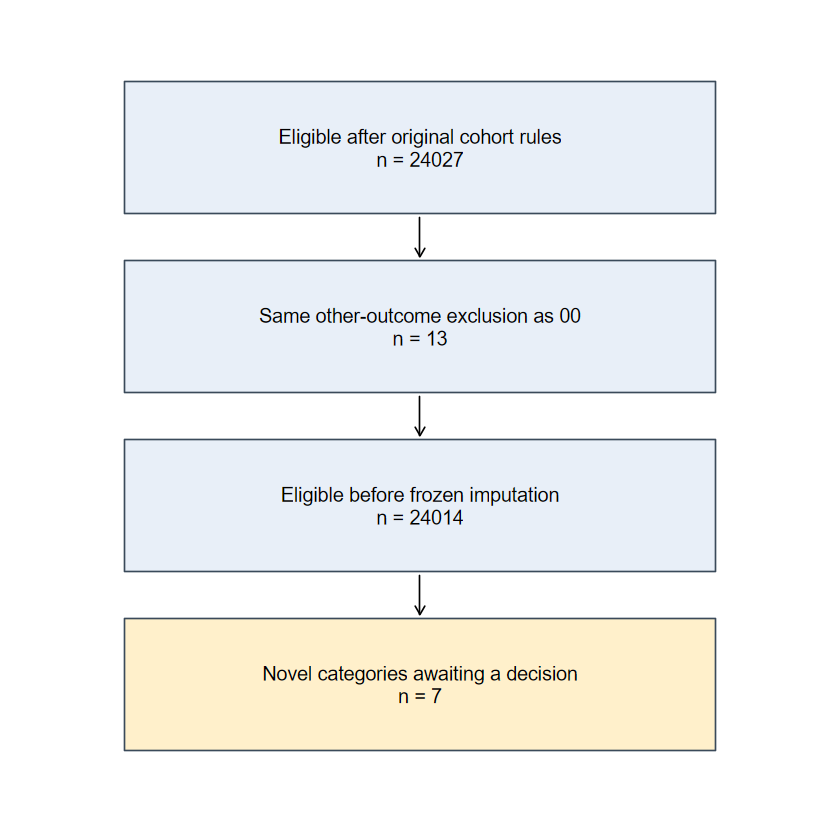

In [13]:
#| label: temporal-cohort-flowchart
#| message: false
.t0 <- Sys.time()
# Display cohort processing and the boundary before frozen imputation; do not save an intermediate figure.
graphics::par(mar = c(0, 0, 0, 0))
graphics::plot.new()
graphics::plot.window(xlim = c(0, 1), ylim = c(0, 1))
flow_labels <- c(paste0("Eligible after original cohort rules\nn = ", nrow(temporal_raw)), paste0("Same other-outcome exclusion as 00\nn = ", sum(other_rows)), paste0("Eligible before frozen imputation\nn = ", nrow(cohort_new)), paste0("Novel categories awaiting a decision\nn = ", sum(novel_categories$N)))
flow_y <- c(0.85, 0.62, 0.39, 0.16)
for (i in seq_along(flow_labels)) {
  graphics::rect(0.12, flow_y[i] - 0.085, 0.88, flow_y[i] + 0.085, col = if (i == 4L) "#fff0cb" else "#e8eff8", border = "#3a4a5a")
  graphics::text(0.5, flow_y[i], flow_labels[i], cex = 0.95)
  if (i < length(flow_labels)) graphics::arrows(0.5, flow_y[i] - 0.09, 0.5, flow_y[i + 1L] + 0.09, length = 0.08)
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


# Shared frozen-model handoff and approved predictor decisions
Notebook 09 supplies `readRDS(source_path("holdout_frozen_models"))$value`: `net$b`, `net$d`, `net$e`, `cif$bp1`, and `cif$bp2`, each with five fitted development models. Its frozen encoding is embedded in temporal-frozen-encoding; probabilities are predicted from its saved models. No temporary script will be sourced by the finished notebook.
The investigator grouped the seven `first_sub_used = dissociatives` records into the existing development category `others`. All seven people are retained. The guard checks this recorded decision and the approved retention of the trained poverty definition before applying frozen imputers.
The primary Table 4 engine preserves horizon-risk Uno C and classical Graf IBS over 0 to the horizon, with temporal-cohort censoring weights. CIF is a supplementary score comparison. The historical corrected IBS/skill bootstrap re-estimates the censoring distribution in every replicate. Predictive recalibration and Riley simulations are omitted from this Table-4 run with a written simplification record; all 1,000 main bootstrap draws are retained.

In [14]:
#| label: temporal-frozen-encoding
#| message: false
.t0 <- Sys.time()
#| message: false
# Reuse the original reference categories, dummy construction and first-substance grouping.
cox_columns <- c(
"adm_age_rec3", "porc_pobr", "dit_m", "national_foreign", 
  "ethnicity", "dg_psiq_cie_10_instudy", "dg_psiq_cie_10_dg", 
  "dx_f3_mood", "dx_f6_personality", "dx_f_any_severe_mental", 
  "any_phys_dx", "polysubstance_strict",
  "sex_rec_woman", "cohabitation_family_of_origin", 
  "cohabitation_with_couple_children", "cohabitation_others", 
  "sub_dep_icd10_status_drug_dependence", 
  "any_violence_1_domestic_violence_sex_abuse", "tr_outcome_referral", 
  "tr_outcome_dropout", "tr_outcome_adm_discharge_rule_violation_undet", 
  "tr_outcome_adm_discharge_adm_reasons", 
  "adm_motive_sanitary_sector", "adm_motive_another_sud_facility_fonodrogas_senda_previene", 
  "adm_motive_justice_sector", "adm_motive_other", "first_sub_used_alcohol", 
  "first_sub_used_cocaine_paste", "first_sub_used_cocaine_powder", "first_sub_used_other",
  "primary_sub_mod_cocaine_paste", "primary_sub_mod_cocaine_powder", 
   "primary_sub_mod_alcohol", "primary_sub_mod_others", 
  "tipo_de_vivienda_rec2_other_unknown", "plan_type_corr_pg_pr", 
  "plan_type_corr_m_pr", "plan_type_corr_pg_pai", "plan_type_corr_m_pai", 
  "occupation_condition_corr24_unemployed", "occupation_condition_corr24_inactive", 
  "marital_status_rec_single", "marital_status_rec_separated_divorced_annulled_widowed", 
  "tenure_status_household_renting", 
  "tenure_status_household_others", 
  "tenure_status_household_stays_temporarily_with_a_relative", 
  "tenure_status_household_illegal_settlement",
  "urbanicity_cat_2_mixed", 
  "urbanicity_cat_1_rural",
  "evaluacindelprocesoteraputico_logro_intermedio", "evaluacindelprocesoteraputico_logro_minimo",
  "eva_consumo_logro_intermedio", "eva_consumo_logro_minimo",
  "eva_fam_logro_intermedio", "eva_fam_logro_minimo",
  "eva_relinterp_logro_intermedio", "eva_relinterp_logro_minimo",
  "eva_ocupacion_logro_intermedio", "eva_ocupacion_logro_minimo",
  "eva_sm_logro_intermedio", "eva_sm_logro_minimo",
  "eva_fisica_logro_intermedio", "eva_fisica_logro_minimo",
  "eva_transgnorma_logro_intermedio", "eva_transgnorma_logro_minimo",
  "prim_sub_freq_rec_2_2_6_days_wk", 
  "prim_sub_freq_rec_3_daily",
  "ed_attainment_corr_2_completed_high_school_or_less", 
  "ed_attainment_corr_3_completed_primary_school_or_less"
)
DUMMY_REFERENCE <- c(
sex_rec = "man",
  plan_type_corr = "pg-pab",
  marital_status_rec = "married/cohabiting",
  cohabitation = "alone",
  sub_dep_icd10_status = "hazardous consumption",
  tr_outcome = "completion",
  adm_motive = "spontaneous consultation",
  tipo_de_vivienda_rec2 = "formal housing",
  occupation_condition_corr24 = "employed",
  any_violence = "0.No domestic violence/sex abuse",
  first_sub_used = "marijuana",
  primary_sub_mod = "marijuana",
  tenure_status_household = "owner/transferred dwellings/pays dividends",
  urbanicity_cat = "3.Urban",
  evaluacindelprocesoteraputico = "logro alto",
  eva_consumo = "logro alto",
  eva_fam = "logro alto",
  eva_relinterp = "logro alto",
  eva_ocupacion = "logro alto",
  eva_sm = "logro alto",
  eva_fisica = "logro alto",
  eva_transgnorma = "logro alto",
  prim_sub_freq_rec = "1.\u22641 day/wk",
  ed_attainment_corr = "1-More than high school"
)
endpoint_columns <- c("readmit_event","readmit_time_from_disch_m","death_event","death_time_from_disch_m")
natural_predictors <- cox_columns[seq_len(12L)]
encode_frozen <- function(data, template, row_ids=seq_len(nrow(data))) {
  needed <- unique(c(natural_predictors,names(DUMMY_REFERENCE)))
  stopifnot(all(needed %in% names(data)), all(needed %in% names(template)), !anyNA(data[needed]), length(row_ids)==nrow(data))
  input <- as.data.frame(data[needed])
  for(v in names(DUMMY_REFERENCE)) {
    observed <- unique(trimws(as.character(template[[v]])))
    ref <- DUMMY_REFERENCE[[v]]
    stopifnot(ref %in% observed)
    levels <- c(ref,observed[observed!=ref])
    values <- trimws(as.character(input[[v]]))
    if(any(!values %in% levels)) stop("New category without development support: ",v)
    input[[v]] <- factor(paste0("_",values),levels=paste0("_",levels))
  }
  cat_cols <- names(input)[vapply(input,function(x) is.character(x)||is.factor(x),logical(1L))]
  mm <- stats::model.matrix(~ ., data=input[cat_cols])
  stopifnot(nrow(mm)==nrow(input),all(is.finite(mm)))
  mm <- as.data.frame(mm[,colnames(mm)!="(Intercept)",drop=FALSE],check.names=FALSE)
  encoded <- janitor::clean_names(cbind(input[setdiff(names(input),cat_cols)],mm))
  other <- intersect(c("first_sub_used_opioids","first_sub_used_others","first_sub_used_hallucinogens","first_sub_used_inhalants","first_sub_used_tranquilizers_hypnotics","first_sub_used_amphetamine_type_stimulants"),names(encoded))
  encoded$first_sub_used_other <- if(length(other)) as.integer(rowSums(encoded[other])>0) else 0L
  stopifnot(all(cox_columns %in% names(encoded)))
  encoded <- encoded[cox_columns]
  available_endpoints <- intersect(endpoint_columns,names(data))
  encoded[available_endpoints] <- data[available_endpoints]
  encoded$center_id <- as.numeric(as.character(data$center_id))
  stopifnot(identical(is.na(encoded$center_id),is.na(data$center_id)))
  encoded$row_id <- row_ids
  encoded$plan_type_strata <- factor(as.character(data$plan_type_corr),levels=sort(unique(as.character(template$plan_type_corr))))
  for(v in intersect(c("readmit_time_from_disch_m","death_time_from_disch_m"),available_endpoints)) encoded[[v]][encoded[[v]]<=0] <- 1e-6
  stopifnot(!anyNA(encoded[setdiff(names(encoded),"center_id")]), nrow(encoded)==nrow(data))
  encoded
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [15]:
#| label: temporal-frozen-imputer-application-functions
#| message: false
.t0 <- Sys.time()
outcome_names <- c("readmit_time_from_disch_m", "readmit_event", "death_time_from_disch_m", "death_event", "readmit_time_from_adm_m", "death_time_from_adm_m")
forbidden <- c(outcome_names, "center_id", "original_row_id", "legacy_row_id", "row_id", "hash_key", "is_train")
assert_predictors <- function(x) {
  bad <- intersect(names(x), forbidden)
  if (length(bad)) stop("Forbidden imputer columns: ", paste(bad, collapse = ", "), call. = FALSE)
  if (anyDuplicated(names(x)) || !ncol(x)) stop("Predictor columns must be unique and nonempty.", call. = FALSE)
  invisible(TRUE)
}
assert_observed <- function(original, completed) {
  stopifnot(identical(names(original), names(completed)), nrow(original) == nrow(completed), !anyNA(completed))
  valid <- vapply(names(original), function(v) {
    keep <- !is.na(original[[v]])
    identical(as.character(original[[v]][keep]), as.character(completed[[v]][keep]))
  }, logical(1L))
  if (!all(valid)) stop("Observed values changed: ", paste(names(valid)[!valid], collapse = ", "), call. = FALSE)
  invisible(TRUE)
}
apply_imputer <- function(fit, x, settings, seed) {
  assert_predictors(x)
  stopifnot(identical(names(x), names(fit$data_raw)))
  unsupported <- setdiff(names(x)[colSums(is.na(x)) > 0L], fit$to_impute)
  if (length(unsupported)) stop("No fitted development imputation model for: ", paste(unsupported, collapse = ", "), call. = FALSE)
  for (v in names(x)) {
    if (is.factor(fit$data_raw[[v]])) {
      novel <- setdiff(unique(as.character(x[[v]][!is.na(x[[v]])])), levels(fit$data_raw[[v]]))
      if (length(novel)) stop("Unseen category in predictor: ", v, call. = FALSE)
      x[[v]] <- factor(as.character(x[[v]]), levels = levels(fit$data_raw[[v]]), ordered = is.ordered(fit$data_raw[[v]]))
    }
  }
  RNGkind("Mersenne-Twister", "Inversion", "Rejection")
  set.seed(seed)
  completed <- stats::predict(fit, newdata = x, pmm.k = settings$pmm_k, iter = settings$predict_iter, num.threads = settings$threads, seed = seed, verbose = 0L)
  assert_observed(x, completed)
  completed
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [16]:
#| label: temporal-original-concordance-and-support-functions
#| message: false
.t0 <- Sys.time()
#' Compute Uno's concordance (C-index) for a predicted score at one time horizon.
#'
#' Uno's C is a time-dependent concordance measure for survival outcomes. It is
#' useful when the prediction target is "risk within X months" rather than a
#' single global ranking. The score argument can be either an absolute risk
#' probability at that horizon or a linear predictor that is comparable within
#' a stratum.
#'
#' @param time    Numeric survival / follow-up times.
#' @param event   Integer event indicator (1 = event, 0 = censored).
#' @param score   Numeric predicted score (higher = more risk, see below).
#' @param horizon Numeric time horizon at which to evaluate concordance.
#' @param stratum Optional factor defining baseline-hazard strata. When given,
#'                comparable pairs are restricted to within the same stratum.
#'
#' @return Scalar Uno's C estimate, or NA_real_ if survival::concordance() fails.
#'
#' Why reverse = TRUE and ymax = horizon?
#' - Uno's C is usually computed by considering only pairs that are comparable
#'   up to the evaluation horizon. Setting ymax = horizon tells the function
#'   to truncate follow-up at the horizon.
#' - For risk predictions, higher scores should mean higher risk, so
#'   reverse = TRUE gives concordance in the correct direction.
uno_c_prediction23 <- function(time, event, score, horizon, stratum = NULL) {
  # Assemble a clean data frame so survival::concordance gets proper types.
  data <- data.frame(
    time = as.numeric(time),
    event = as.integer(event),
    score = as.numeric(score)
  )
  # If a stratum was supplied, add it as a factor to the data frame.
  if (!is.null(stratum)) data$stratum <- factor(stratum)
  # Build the formula. Without a stratum we model risk directly from the score.
  # With strata, we restrict comparable pairs to within the same stratum.
  formula <- if (is.null(stratum)) {
    survival::Surv(time, event) ~ score
  } else {
    survival::Surv(time, event) ~ score + strata(stratum)
  }
  environment(formula) <- asNamespace("survival")
  # Try to compute concordance. Return NA if survival::concordance errors.
  tryCatch(
    unname(
      survival::concordance(
        formula,
        data = data,
        timewt = "n/G2",  # Original Uno-type time weighting.
        reverse = TRUE,     # Higher score = higher risk.
        ymax = horizon      # Evaluate only up to the specified horizon.
      )$concordance
    ),
    error = function(error) NA_real_
  )
}
#' Summarise a point estimate with bootstrap 95% percentile intervals.
#'
#' If replicates is NULL, the function is used for diagnostics where bootstrap
#' intervals are not desired or not possible (e.g., within-strata estimates).
#'
#' @param point       Numeric vector of point estimates, one per horizon.
#' @param replicates  Matrix of bootstrap replicates, or NULL. Rows are horizons,
#'                    columns are bootstrap samples.
#' @param metric_names Character vector of labels for each horizon.
#'
#' @return data.frame with one row per horizon: metric, estimate, lower_95, upper_95.
bootstrap_uno_summary <- function(point, replicates, metric_names) {
  if (is.null(replicates)) {
    # No bootstrap requested: return NA bounds.
    lower <- upper <- rep(NA_real_, length(point))
  } else {
    # Compute 2.5% and 97.5% quantiles across bootstrap columns for each horizon.
    lower <- apply(replicates, 1L, stats::quantile, 0.025, na.rm = TRUE, names = FALSE)
    upper <- apply(replicates, 1L, stats::quantile, 0.975, na.rm = TRUE, names = FALSE)
  }
  data.frame(
    metric = metric_names,
    estimate = point,
    lower_95 = lower,
    upper_95 = upper
  )
}
#' Evaluate Uno's C using pooled absolute risk at each horizon.
#'
#' risk_horizons is expected to be a matrix with one column per time horizon,
#' where each entry is the predicted absolute risk for that individual at that
#' horizon. The C-index is computed at each horizon using the corresponding risk
#' column and the matching horizon value.
#'
#' @param risk_horizons     n x k matrix of predicted absolute risks.
#'                          Columns correspond to elements of horizons.
#' @param time              Follow-up times.
#' @param event             Event indicators.
#' @param horizons          Vector of time horizons (e.g., c(12, 24, 36)).
#' @param bootstrap_indices Optional list of bootstrap index vectors. If NULL,
#'                          no bootstrap intervals are computed.
#' @param label             Label used for console output.
#' @param parallel          If TRUE (and future.apply is installed), distribute
#'                          the bootstrap replicates over a future plan (set
#'                          future::plan(future::multisession, workers = N) first).
#'
#' @return List with:
#'   - summary: data.frame of estimates and 95% percentile intervals.
#'   - replicates: matrix of bootstrap estimates (or NULL).
#'   - score: description of what score was used.
evaluate_uno_absolute_risk <- function(
    risk_horizons,
    time,
    event,
    horizons = HORIZONS,
    bootstrap_indices = NULL,
    label = "Uno C",
    parallel = FALSE) {
  # Print a progress header.
  cat("\n--- Evaluating", label, "on absolute risk ---\n")
  cat("Horizons:", paste(horizons, collapse = ", "), "months\n")
  cat("Observations:", length(time), "; events:", sum(event), "\n")
  flush.console()
  # Ensure risk_horizons is a matrix and has the expected dimensions.
  risk_horizons <- as.matrix(risk_horizons)
  stopifnot(
    nrow(risk_horizons) == length(time),
    ncol(risk_horizons) == length(horizons)
  )
  # Create human-readable labels like "12 months", "24 months", etc.
  metric_names <- paste0(horizons, " months")
  # Helper function: compute Uno's C for a subset of rows (used both for the
  # full sample and for each bootstrap sample).
  estimate <- function(index) {
    vapply(seq_along(horizons), function(j) {
      uno_c_prediction23(
        time[index],                # Subset of follow-up times.
        event[index],               # Subset of event indicators.
        risk_horizons[index, j],    # Risk predictions for this horizon.
        horizons[[j]]               # Matching time horizon.
      )
    }, numeric(1))
  }
  # Point estimates on the full data.
  point <- estimate(seq_along(time))
  cat("Point estimates:\n")
  print(data.frame(horizon = metric_names, uno_c = point))
  flush.console()
  # Compute bootstrap replicates if bootstrap_indices were supplied.
  if (is.null(bootstrap_indices)) {
    replicates <- NULL
  } else {
    use_par <- isTRUE(parallel) && requireNamespace("future.apply", quietly = TRUE)
    cat("Running", length(bootstrap_indices), "bootstrap replicates (parallel =", use_par, ")...\n")
    flush.console()
    replicate_list <- if (use_par) {
      future.apply::future_lapply(bootstrap_indices, estimate, future.seed = TRUE)
    } else {
      result <- vector("list", length(bootstrap_indices))
      for (b in seq_along(bootstrap_indices)) {
        result[[b]] <- estimate(bootstrap_indices[[b]])
        progress_update(b, length(bootstrap_indices), label)
      }
      result
    }
    # One column per bootstrap sample, one row per horizon (same layout the
    # sequential loop always produced).
    replicates <- matrix(
      unlist(replicate_list),
      nrow = length(point),
      ncol = length(bootstrap_indices)
    )
  }
  # Summarise point estimates and percentile intervals.
  summary <- bootstrap_uno_summary(point, replicates, metric_names)
  cat("\n", label, "summary:\n")
  print(summary)
  flush.console()
  list(
    summary = summary,
    replicates = replicates,
    score = "pooled absolute risk at the matching horizon"
  )
}
#' Evaluate Uno's C using the pooled linear predictor, restricted by stratum.
#'
#' This is used when predictions are linear predictors from a stratified model
#' (e.g., separate baseline hazards per stratum). A linear predictor is only
#' comparable between subjects in the same stratum, so we pass stratum to
#' uno_c_prediction23(). No bootstrap intervals are produced here.
#'
#' @param lp_by_imputation List of linear predictor vectors, one per imputation.
#'                         They are averaged to produce a pooled linear predictor.
#' @param time             Follow-up times.
#' @param event            Event indicators.
#' @param stratum          Factor defining the baseline-hazard strata.
#' @param horizons         Vector of time horizons.
#'
#' @return List with summary and a description of the score.
#' Evaluate Uno's C using the pooled linear predictor, with NO stratum restriction.
#'
#' Companion to evaluate_uno_absolute_risk() (risk-based, global) and the
#' within-strata LP function below: this isolates the effect of the
#' within-strata pair restriction from the effect of score type (LP vs risk),
#' by giving the LP score its own global (unrestricted) estimate with bootstrap.
#'
#' @param lp_by_imputation  List of linear predictor vectors, one per imputation.
#'                          Averaged to a pooled linear predictor.
#' @param time              Follow-up times.
#' @param event             Event indicators.
#' @param horizons          Vector of time horizons.
#' @param bootstrap_indices Optional list of bootstrap index vectors. If NULL,
#'                          no bootstrap intervals are computed.
#' @param label             Label used for console output.
#'
#' @return List with summary, replicates (or NULL), and a description of the score.
evaluate_uno_lp_global <- function(
    lp_by_imputation,
    time,
    event,
    horizons = HORIZONS,
    bootstrap_indices = NULL,
    label = "Global LP-based Uno C") {
  cat("\n--- Evaluating", label, "---\n")
  cat("Horizons:", paste(horizons, collapse = ", "), "months\n")
  cat("Observations:", length(time), "; events:", sum(event), "\n")
  flush.console()
  # Pool linear predictors across imputations by simple averaging.
  pooled_lp <- Reduce(`+`, lp_by_imputation) / length(lp_by_imputation)
  metric_names <- paste0(horizons, " months")
  # Helper: compute Uno's C at each horizon for a subset of rows (full sample
  # or one bootstrap sample). No stratum argument, so pairs are compared globally.
  estimate <- function(index) {
    vapply(horizons, function(horizon) {
      uno_c_prediction23(
        time = time[index],
        event = event[index],
        score = pooled_lp[index],
        horizon = horizon
      )
    }, numeric(1))
  }
  point <- estimate(seq_along(time))
  cat("Point estimates:\n")
  print(data.frame(horizon = metric_names, uno_c = point))
  flush.console()
  if (is.null(bootstrap_indices)) {
    replicates <- NULL
  } else {
    cat("Running", length(bootstrap_indices), "bootstrap replicates...\n")
    flush.console()
    replicates <- matrix(NA_real_, nrow = length(point), ncol = length(bootstrap_indices))
    for (b in seq_along(bootstrap_indices)) {
      replicates[, b] <- estimate(bootstrap_indices[[b]])
      progress_update(b, length(bootstrap_indices), label)
    }
  }
  summary <- bootstrap_uno_summary(point, replicates, metric_names)
  cat("\n", label, "summary:\n")
  print(summary)
  flush.console()
  list(
    summary = summary,
    replicates = replicates,
    score = "pooled linear predictor; no stratum restriction"
  )
}
#' Evaluate Uno's C using the pooled linear predictor, restricted by stratum.
#'
#' This is used when predictions are linear predictors from a stratified model
#' (e.g., separate baseline hazards per stratum). A linear predictor is only
#' comparable between subjects in the same stratum, so we pass stratum to
#' uno_c_prediction23(). Bootstrap intervals are produced when bootstrap_indices
#' is supplied, so this is directly comparable to evaluate_uno_lp_global() above.
#'
#' @param lp_by_imputation List of linear predictor vectors, one per imputation.
#'                         They are averaged to produce a pooled linear predictor.
#' @param time             Follow-up times.
#' @param event            Event indicators.
#' @param stratum          Factor defining the baseline-hazard strata.
#' @param horizons         Vector of time horizons.
#' @param bootstrap_indices Optional list of bootstrap index vectors. If NULL,
#'                         no bootstrap intervals are computed.
#' @param label            Label used for console output.
#'
#' @return List with summary, replicates (or NULL), and a description of the score.
evaluate_uno_within_strata <- function(
    lp_by_imputation,
    time,
    event,
    stratum,
    horizons = HORIZONS,
    bootstrap_indices = NULL,
    label = "Within-stratum Uno C") {
  cat("\n--- Evaluating", label, "---\n")
  cat("Horizons:", paste(horizons, collapse = ", "), "months\n")
  cat("Strata:", dplyr::n_distinct(stratum), "unique values\n")
  flush.console()
  # Pool linear predictors across imputations by simple averaging.
  pooled_lp <- Reduce(`+`, lp_by_imputation) / length(lp_by_imputation)
  metric_names <- paste0(horizons, " months")
  # Helper: compute within-stratum Uno's C at each horizon for a subset of rows.
  estimate <- function(index) {
    vapply(horizons, function(horizon) {
      uno_c_prediction23(
        time = time[index],
        event = event[index],
        score = pooled_lp[index],
        horizon = horizon,
        stratum = stratum[index]
      )
    }, numeric(1))
  }
  point <- estimate(seq_along(time))
  cat("Point estimates:\n")
  print(data.frame(horizon = metric_names, uno_c = point))
  flush.console()
  if (is.null(bootstrap_indices)) {
    replicates <- NULL
  } else {
    cat("Running", length(bootstrap_indices), "bootstrap replicates...\n")
    flush.console()
    replicates <- matrix(NA_real_, nrow = length(point), ncol = length(bootstrap_indices))
    for (b in seq_along(bootstrap_indices)) {
      replicates[, b] <- estimate(bootstrap_indices[[b]])
      progress_update(b, length(bootstrap_indices), label)
    }
  }
  summary <- bootstrap_uno_summary(point, replicates, metric_names)
  cat("Within-stratum Uno C summary:\n")
  print(summary)
  flush.console()
  list(
    summary = summary,
    replicates = replicates,
    score = "pooled linear predictor; comparable pairs restricted within baseline strata"
  )
}
# Compute Kish-type effective sample size from a vector of positive weights.
# The effective sample size (ESS) tells you how much information your weighted
# sample actually carries. When weights are very unequal, ESS can be much
# smaller than the number of rows.
# Formula: ESS = (sum(weights))^2 / sum(weights^2).
kish_effective_information <- function(weights) {
  weights <- as.numeric(weights)
  # Keep only finite, positive weights.
  weights <- weights[is.finite(weights) & weights > 0]
  # If there are no valid weights or all weights are zero, ESS is undefined.
  if (!length(weights) || sum(weights^2) == 0) return(NA_real_)
  sum(weights)^2 / sum(weights^2)
}
# Compute the coefficient of variation of positive weights.
# CV = SD / mean. A large CV means some subjects receive much more weight
# than others, which can destabilize weighted estimates.
weight_cv <- function(weights) {
  weights <- as.numeric(weights)
  # Keep only finite, positive weights.
  weights <- weights[is.finite(weights) & weights > 0]
  # Need at least two weights and a non-zero mean to compute CV.
  if (length(weights) < 2L || mean(weights) == 0) return(NA_real_)
  stats::sd(weights) / mean(weights)
}
# Summarise follow-up structure and inverse-probability-of-censoring
# weighting (IPCW) diagnostics for each prediction horizon.
# This function checks whether the validation cohort has enough support
# (follow-up and events) to reliably evaluate predictions at each horizon,
# and reports how much the IPCW weights inflate or concentrate information.
validation_window_support <- function(
    time,
    event,
    potential_followup,
    horizons = HORIZONS,
    verbose = TRUE) {
  time <- as.numeric(time)
  event <- as.integer(event)
  # Estimate the censoring survival function G(t) = P(C > t).
  # This is reused from a related function (censoring_survival_function).
  G <- censoring_survival_function(time, event, minimum = 1e-8)
  if (verbose) {
    cat("\n--- Validation window support and IPCW diagnostics ---\n")
    cat("Observations:", length(time), "; events:", sum(event), "\n")
    cat("Horizons:", paste(horizons, collapse = ", "), "months\n")
    flush.console()
  }
  # For each horizon, build one row of diagnostics.
  result <- dplyr::bind_rows(lapply(horizons, function(horizon) {
    # Subjects who had the event at or before the horizon.
    event_by_horizon <- event == 1L & time <= horizon
    # Subjects who were still at risk and event-free at the horizon.
    # Note: uses >= horizon, so ties at the horizon count as event-free.
    event_free_at_horizon <- time >= horizon
    # Subjects whose event status is known at the horizon: either event
    # occurred before horizon, or they were still under follow-up at horizon.
    known <- event_by_horizon | event_free_at_horizon
    # IPCW weights used to reconstruct the status at the horizon (event or not).
    # Events are weighted by 1 / G(event_time), and survivors by 1 / G(horizon).
    status_weights <- numeric(length(time))
    status_weights[event_by_horizon] <- 1 / G(time[event_by_horizon], before = TRUE)
    status_weights[event_free_at_horizon] <- 1 / G(horizon, before = FALSE)
    # IPCW weights used specifically for events in Uno's concordance estimator.
    # These are squared inverse censoring probabilities: 1 / G(time)^2.
    uno_event_weights <- if (any(event_by_horizon)) {
      1 / G(time[event_by_horizon], before = TRUE)^2
    } else numeric()
    data.frame(
      horizon_months = horizon,
      n_at_time_zero = length(time),
      readmissions = sum(event_by_horizon),
      # Average number of events per model coefficient parameter. This helps
      # judge whether the event count is adequate relative to model complexity.
      events_per_coefficient_parameter = sum(event_by_horizon) / MODEL_COEFFICIENT_PARAMETERS,
      # Subjects censored before the horizon; their status at the horizon is unknown.
      censored_event_free_before_horizon = sum(event == 0L & time < horizon),
      percent_censored_before_horizon = 100 * mean(event == 0L & time < horizon),
      # Subjects still at risk and event-free at the exact horizon.
      still_at_risk_at_horizon = sum(time >= horizon),
      # Subjects whose potential follow-up time reached at least the horizon,
      # which is a stricter measure of whether the data can support evaluation
      # at that horizon. Returns NA if potential_followup is not provided.
      potential_followup_at_least_horizon = if (all(is.na(potential_followup))) {
        NA_integer_
      } else sum(potential_followup >= horizon, na.rm = TRUE),
      # Number of subjects whose horizon status is known.
      known_status_at_horizon = sum(known),
      # Probability of remaining uncensored at the horizon.
      censoring_survival_at_horizon = G(horizon, before = FALSE),
      # Person-months of observed follow-up up to the horizon.
      person_months_observed = sum(pmin(time, horizon)),
      # Effective sample size of the status IPCW weights (Kish-type).
      status_ipcw_kish_type_ess = kish_effective_information(status_weights),
      # ESS as a fraction of the original sample size.
      status_ipcw_ess_fraction_of_n = kish_effective_information(status_weights) / length(time),
      # Coefficient of variation of the status IPCW weights.
      status_ipcw_weight_cv = weight_cv(status_weights),
      # 99th percentile and maximum of the status IPCW weights.
      # These flag extreme weights that might dominate the weighted estimate.
      status_ipcw_weight_p99 = if (any(status_weights > 0)) {
        unname(stats::quantile(status_weights[status_weights > 0], 0.99, names = FALSE))
      } else NA_real_,
      status_ipcw_weight_max = if (any(status_weights > 0)) max(status_weights) else NA_real_,
      # Effective sample size of the Uno event weights.
      uno_event_weight_kish_type_ess = kish_effective_information(uno_event_weights),
      # Uno event ESS as a fraction of the number of observed events.
      uno_event_ess_fraction_of_events = if (sum(event_by_horizon) > 0) {
        kish_effective_information(uno_event_weights) / sum(event_by_horizon)
      } else NA_real_,
      # Coefficient of variation and extremes of the Uno event weights.
      uno_event_weight_cv = weight_cv(uno_event_weights),
      uno_event_weight_p99 = if (length(uno_event_weights)) {
        unname(stats::quantile(uno_event_weights, 0.99, names = FALSE))
      } else NA_real_,
      uno_event_weight_max = if (length(uno_event_weights)) max(uno_event_weights) else NA_real_
    )
  }))
  if (verbose) {
    cat("\nValidation window support summary:\n")
    print(result)
    flush.console()
  }
  result
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [17]:
#| label: temporal-original-skill-functions
#| message: false
.t0 <- Sys.time()
ibsskill_censoring_G_at <- function(time, event, g_min = 0.05) {
  fit <- survival::survfit(survival::Surv(time, 1L - event) ~ 1)
  function(query) {
    requested <- pmax(as.numeric(query), 0)
    unique_times <- sort(unique(requested))
    g <- as.numeric(summary(fit, times = unique_times, extend = TRUE)$surv)
    stopifnot(length(g) == length(unique_times))
    pmax(g[match(requested, unique_times)], g_min)
  }
}
# Per-subject IPCW squared-error contribution at every grid node, for a given
# censoring function G_at (already fit on whichever sample is in scope).
# Identical arithmetic to the .contrib()/contrib() local functions already in
# both notebook cells; extracted here so it can be called fresh inside every
# bootstrap replicate instead of once outside the loop.
#
# Performance note: this is fully matrix-vectorised, with NO per-grid-node R
# loop and NO ifelse() call. An earlier version looped over grid nodes
# (calling ifelse() once per node) and was too slow to be usable at
# B = 1000 on the ~26,000-row readmission cohort with a ~150-point fine grid
# (confirmed by timing during development: it did not finish a 100-replicate
# test in several minutes). G at every grid node is looked up in ONE batched
# call (G_at(grid_pos)); the per-subject event-time lookup (g_event) is
# likewise a single batched call; and the event/after-horizon weight
# assignment is done as two whole-matrix logical-index writes instead of a
# per-node ifelse(), which is what actually removed the bottleneck (matrix
# recycling instead of an R-level loop over ~150 grid nodes).
ibsskill_per_subject_contrib <- function(time, event, surv_mat, grid_pos, G_at, eps = 1e-8) {
  n <- length(time); k <- length(grid_pos)
  g_event <- G_at(pmax(time - eps, 0))          # length n: G just before each subject's own time
  g_grid <- G_at(grid_pos)                       # length k: G at each grid node
  is_event <- (event == 1L)
  time_le <- outer(time, grid_pos, "<=")         # n x k: TRUE where the subject's time is <= that node
  time_gt <- !time_le                            # n x k: TRUE where the subject is still event-free at that node
  event_before <- time_le & is_event             # n x k: TRUE where the subject had the event at/before that node
  weight <- matrix(0, n, k)
  weight[event_before] <- matrix(1 / g_event, n, k)[event_before]
  weight[time_gt] <- matrix(1 / g_grid, n, k, byrow = TRUE)[time_gt]
  outcome <- matrix(as.numeric(time_gt), n, k)   # 1 if still event-free at the node, 0 otherwise
  weight * (outcome - surv_mat)^2
}
# Bootstrap with G refit inside every replicate. surv_model / surv_null are
# the (already computed, NOT refit) prediction matrices for the model of
# interest and the intercept-only null, both n x length(grid_pos), indexed by
# the same resample as time/event -- only the CENSORING model is refit per
# replicate, since that is the piece the fixed-G shortcut held constant.
# weight_list is a named list of grid_pos x length(horizons) trapezoid-weight
# matrices (one per integration convention, e.g. list(classical = W_cl,
# pred23 = W_p23)); weights depend only on the (fixed) grid, not on the data,
# so they are computed once outside this function and passed in unchanged.
# Returns a named list of B x length(horizons) matrices, one per
# (convention, arm) combination, named "<convention>_model" / "<convention>_null" --
# a drop-in replacement for the notebooks' existing CW / bt / boot_mat objects.
#
# indices: optional, a pre-built list of length-n resample-index vectors (as
# produced by make_bootstrap_indices() in prediction26, or the notebook's own
# shared `bootstrap_indices`). When supplied, B/seed are ignored and these
# exact resamples are used, so this cell's bootstrap uses the SAME draws as
# every other bootstrap in the notebook (paired, not just similarly-sized).
# When NULL, B fresh resamples are drawn here with `seed` (matching
# prediction27's own self-contained IBS_SEED/IBS_B convention).
ibsskill_bootstrap_refit <- function(time, event, surv_model, surv_null, grid_pos, weight_list,
                                     B = 1000L, seed = 2125L, g_min = 0.05, parallel = FALSE,
                                     indices = NULL) {
  n <- length(time)
  stopifnot(length(event) == n, nrow(surv_model) == n, nrow(surv_null) == n,
           is.list(weight_list), length(weight_list) >= 1L)
  weight_names <- names(weight_list)
  stopifnot(!is.null(weight_names), all(nzchar(weight_names)))
  col_labels <- unlist(lapply(weight_names, function(wn) {
    W <- weight_list[[wn]]
    c(paste0(wn, "_model_", seq_len(ncol(W))), paste0(wn, "_null_", seq_len(ncol(W))))
  }))
  one_rep <- function(bi) {
    t <- time[bi]; e <- event[bi]
    Sm <- surv_model[bi, , drop = FALSE]; Sn <- surv_null[bi, , drop = FALSE]
    # The one line that fixes the problem: G is fit fresh on THIS replicate's
    # resampled (t, e), not reused from the full-sample fit.
    G_at <- ibsskill_censoring_G_at(t, e, g_min)
    Cm <- ibsskill_per_subject_contrib(t, e, Sm, grid_pos, G_at)
    Cn <- ibsskill_per_subject_contrib(t, e, Sn, grid_pos, G_at)
    values <- unlist(lapply(weight_names, function(wn) {
      W <- weight_list[[wn]]
      c(as.numeric(colMeans(Cm %*% W)), as.numeric(colMeans(Cn %*% W)))
    }))
    stats::setNames(values, col_labels)
  }
  if (!is.null(indices)) {
    stopifnot(is.list(indices), length(indices) >= 1L, all(lengths(indices) == n))
    idx <- indices
  } else {
    set.seed(seed)
    idx <- lapply(seq_len(B), function(b) sample.int(n, n, replace = TRUE))
  }
  use_parallel <- isTRUE(parallel) && requireNamespace("future.apply", quietly = TRUE)
  replicate_list <- if (use_parallel) {
    future.apply::future_lapply(idx, one_rep, future.seed = TRUE)
  } else lapply(idx, one_rep)
  M <- do.call(rbind, replicate_list)
  result <- list()
  for (wn in weight_names) {
    W <- weight_list[[wn]]
    result[[paste0(wn, "_model")]] <- M[, paste0(wn, "_model_", seq_len(ncol(W))), drop = FALSE]
    result[[paste0(wn, "_null")]] <- M[, paste0(wn, "_null_", seq_len(ncol(W))), drop = FALSE]
  }
  result
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


In [18]:
#| label: temporal-verified-brier-engine
#| message: false
.t0 <- Sys.time()
# Reuse one censoring curve per sample, retaining the original left-limit lookup and 0.01 floor.
temporal_brier_curve <- function(time, event, risk, grid, minimum = 0.01) {
  stopifnot(nrow(risk) == length(time), ncol(risk) == length(grid))
  G <- censoring_survival_function(time, event, minimum)
  g_event <- G(time, before = TRUE)
  g_grid <- G(grid)
  vapply(seq_along(grid), function(j) {
    before <- event == 1L & time <= grid[j]
    after <- time > grid[j]
    weight <- numeric(length(time))
    weight[before] <- 1 / g_event[before]
    weight[after] <- 1 / g_grid[j]
    mean(weight * (as.numeric(after) - (1 - risk[, j]))^2)
  }, numeric(1L))
}
temporal_integrals <- function(curve, grid, horizons = HORIZONS, convention = "classical") {
  vapply(horizons, function(h) {
    nodes <- if (convention == "classical") grid[grid <= h] else c(3, 6, 12, 36)[c(3, 6, 12, 36) <= h]
    y <- curve[match(nodes, grid)]
    stopifnot(length(nodes) >= 2L, !anyNA(y))
    if (convention == "classical" && nodes[1L] > 0) { nodes <- c(0, nodes); y <- c(0, y) }
    denominator <- if (convention == "classical") h else diff(range(nodes))
    sum(diff(nodes) * (head(y, -1L) + tail(y, -1L)) / 2) / denominator
  }, numeric(1L))
}
# Check ties, event/censoring boundaries and the censoring floor using artificial subjects.
local({
  tt <- rep(c(0.25, 0.5, 1, 2, 3, 4, 6, 12, 36, 40), 12)
  ee <- rep(c(1L, 0L, 1L, 0L, 0L, 0L, 1L, 0L, 0L, 1L), 12)
  risk <- 1 - exp(-outer(seq_along(tt) / 5000 + 0.01, GRID))
  original <- brier_curve(tt, ee, risk, GRID)
  reused_G <- temporal_brier_curve(tt, ee, risk, GRID)
  old_integral <- ibs_to_horizons(tt, ee, risk, GRID)$summary$ibs
  idx <- rev(seq_along(tt))
  differences <- c(max(abs(original - reused_G)), max(abs(old_integral - temporal_integrals(reused_G, GRID))), max(abs(temporal_brier_curve(tt[idx], ee[idx], risk[idx, ], GRID) - reused_G)))
  stopifnot(all(differences < 1e-14))
  show_table(data.frame(Control = c("Brier: one G per sample", "Classical integral", "Unsorted subjects"), Maximum_absolute_difference = differences), "Synthetic controls; no study result")
})
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Control,Maximum_absolute_difference
Brier: one G per sample,0
Classical integral,0
Unsorted subjects,0


Elapsed: 0.003 minutes


In [19]:
#| label: temporal-execution-guard
#| message: false
.t0 <- Sys.time()
# A consistent poverty-source decision must precede new frozen-predictor application.
if(!identical(settings$poverty_definition_decision,"retain_frozen_for_primary")) stop("Pending decision: poverty source years must remain consistent with development; see docs/11_explicacion_y_sensibilidad.md.",call.=FALSE)
# Require the explicit handling of the seven unsupported first-substance categories.
policy <- settings$temporal_novel_category
if (is.null(policy) || identical(policy, "pending")) stop("Seven temporal first-substance categories await a decision: other, impute_missing or omit_prediction. No frozen imputer has been applied.")
stopifnot(policy %in% c("other", "impute_missing", "omit_prediction"), !length(unsupported_missing))
if (nrow(novel_categories)) stopifnot(nrow(novel_categories) == 1L, novel_categories$Variable == "first_sub_used", novel_categories$Value == "dissociatives", novel_categories$N == 7L)
novel_rows <- !is.na(cohort_new$first_sub_used) & cohort_new$first_sub_used == "dissociatives"
category_decision <- data.frame(Variable = "first_sub_used", Original_value = "dissociatives", Development_value = if (policy == "other") "others" else NA_character_, N = sum(novel_rows), Decision = policy)
prediction_cohort <- if (policy == "omit_prediction") cohort_new[!novel_rows, , drop = FALSE] else cohort_new
if (policy == "impute_missing") prediction_cohort$first_sub_used[novel_rows] <- NA_character_
if (policy == "other") {
  stopifnot("others" %in% levels(clean_preparation$development$first_sub_used))
  prediction_cohort$first_sub_used <- as.character(prediction_cohort$first_sub_used)
  prediction_cohort$first_sub_used[novel_rows] <- "others"
  stopifnot(sum(novel_rows) == 7L, all(prediction_cohort$first_sub_used[novel_rows] == "others"))
}
stopifnot(!anyDuplicated(prediction_cohort$hash_key))
x_temporal <- as.data.frame(prediction_cohort[predictor_names])
# Apply development storage classes only after validating original observed category labels.
for (v in predictor_names) {
  ref <- clean_preparation$development[[v]]
  original <- x_temporal[[v]]
  if (is.factor(ref)) {
    stopifnot(all(is.na(original) | as.character(original) %in% levels(ref)))
    x_temporal[[v]] <- factor(as.character(original), levels = levels(ref), ordered = is.ordered(ref))
  } else if (is.integer(ref)) x_temporal[[v]] <- as.integer(original) else if (is.logical(ref)) x_temporal[[v]] <- as.logical(original) else if (is.numeric(ref)) x_temporal[[v]] <- as.numeric(original)
  stopifnot(identical(is.na(original), is.na(x_temporal[[v]])))
}
assert_predictors(x_temporal)
stopifnot(all(c("holdout_frozen_models", "frozen_imputers", "cox_development_matrices") %in% names(config$sources)))
imputer_paths <- vapply(config$sources$frozen_imputers, resolve_path, character(1L))
stopifnot(length(imputer_paths) == 5L, all(file.exists(imputer_paths)), file.exists(source_path("holdout_frozen_models")))
imputation_settings <- config$imputation
imputation_settings$threads <- 1L
imputation_signature <- substr(digest::digest(list(input_hashes, clean_preparation$provenance, category_decision, imputation_settings, file.info(imputer_paths)[c("size", "mtime")], body(recode_temporal_predictors), body(encode_frozen), method = "frozen_temporal_v1"), algo = "sha256"), 1L, 12L)
model_sha256 <- digest::digest(file = source_path("holdout_frozen_models"), algo = "sha256")
analysis_signature <- substr(digest::digest(list(imputation_signature, model_sha256, settings, GRID, method = "temporal_original_pseudovalue_G01_skillG05_v1"), algo = "sha256"), 1L, 12L)
new_cohort_flow <- rbind(new_cohort_flow, data.frame(Stage = "Without prediction by explicit novel-category decision", N = if (policy == "omit_prediction") sum(novel_rows) else 0L), data.frame(Stage = "Prediction cohort", N = nrow(prediction_cohort)))
show_table(category_decision, "Investigator decision: dissociatives grouped with other first substances; all seven people retained")
show_table(new_cohort_flow, "Final temporal prediction coverage")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Variable,Original_value,Development_value,N,Decision
first_sub_used,dissociatives,others,7,other


Stage,N
Original eligible follow-up cohort,24027
"Excluded: other treatment outcome, as in 00",13
Eligible for development-only imputation,24014
Historical complete-case benchmark,23594
Without prediction by explicit novel-category decision,0
Prediction cohort,24014


Elapsed: 1.089 minutes


In [20]:
#| label: temporal-apply-five-frozen-imputers
#| message: false
.t0 <- Sys.time()
# Apply one saved development imputer at a time; never train or update a forest here.
completed_temporal <- vector("list", length(imputer_paths))
encoded_temporal <- vector("list", length(imputer_paths))
imputation_resources <- vector("list", length(imputer_paths))
for (i in seq_along(imputer_paths)) {
  start <- Sys.time()
  path <- cache_path(paste0("temporal10_completed_encoded_imp", i), imputation_signature)
  available <- as.numeric(ps::ps_system_memory()[["avail"]]) / 1024^3
  stopifnot(length(available) == 1L, is.finite(available))
  message(sprintf("Frozen imputer %d: free RAM %.2f GiB; one worker, one thread; reserve %.1f GiB", i, available, settings$reserve_memory_gib))
  stopifnot(available >= settings$reserve_memory_gib + 6)
  one <- cache_object(paste0("temporal10_completed_encoded_imp", i), function() {
    saved <- readRDS(imputer_paths[i])
    stopifnot(identical(saved$metadata$provenance, clean_preparation$provenance), saved$metadata$imputation == i, identical(saved$fit$data_raw, clean_preparation$development))
    completed <- apply_imputer(saved$fit, x_temporal, imputation_settings, SEED + i - 1L)
    data <- completed
    data$center_id <- prediction_cohort$id_centro
    data$readmit_time_from_disch_m <- prediction_cohort$readmit_time_from_disch_m
    data$readmit_event <- prediction_cohort$readmit_event
    encoded <- encode_frozen(data, saved$fit$data, seq_len(nrow(data)))
    stopifnot(!any(grepl("^death_", names(encoded))))
    list(completed = completed, encoded = encoded, hash_key = prediction_cohort$hash_key, imputation = i)
  }, signature = imputation_signature)
  stopifnot(identical(one$hash_key, prediction_cohort$hash_key), one$imputation == i)
  assert_observed(x_temporal, one$completed)
  completed_temporal[[i]] <- one$completed
  encoded_temporal[[i]] <- one$encoded
  stopifnot(nrow(one$encoded) == nrow(prediction_cohort), identical(one$encoded$readmit_event, prediction_cohort$readmit_event))
  imputation_resources[[i]] <- data.frame(Imputation = i, Rows = nrow(one$encoded), Missing_after = sum(is.na(one$completed)), Elapsed_minutes = as.numeric(difftime(Sys.time(), start, units = "mins")), Process_RSS_GiB = as.numeric(ps::ps_memory_info()[["rss"]]) / 1024^3, Cache = if (path %in% written) "written" else "reused")
  rm(one)
  invisible(gc())
}
show_table(do.call(rbind, imputation_resources), "Frozen imputation coverage and resources")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Frozen imputer 1: free RAM 59.50 GiB; one worker, one thread; reserve 20.0 GiB



Frozen imputer 2: free RAM 58.49 GiB; one worker, one thread; reserve 20.0 GiB



Frozen imputer 3: free RAM 58.49 GiB; one worker, one thread; reserve 20.0 GiB



Frozen imputer 4: free RAM 58.39 GiB; one worker, one thread; reserve 20.0 GiB



Frozen imputer 5: free RAM 58.21 GiB; one worker, one thread; reserve 20.0 GiB



Imputation,Rows,Missing_after,Elapsed_minutes,Process_RSS_GiB,Cache
1,24014,0,0.5161,4.2259,written
2,24014,0,0.5019,4.1885,written
3,24014,0,0.4574,4.3664,written
4,24014,0,0.5236,4.6920,written
5,24014,0,0.4680,4.6466,written


Elapsed: 2.502 minutes


In [21]:
#| label: temporal-predict-from-notebook09-frozen-models
#| message: false
.t0 <- Sys.time()
# Predict from the already frozen handoff; no coxph or CSC fitting occurs here.
train_list <- readRDS(source_path("cox_development_matrices"))$value
stopifnot(length(train_list) == 5L)
for (i in seq_along(train_list)) stopifnot(identical(train_list[[i]]$readmit_event, train_list[[1]]$readmit_event), identical(train_list[[i]]$readmit_time_from_disch_m, train_list[[1]]$readmit_time_from_disch_m))
available <- as.numeric(ps::ps_system_memory()[["avail"]]) / 1024^3
stopifnot(length(available) == 1L, is.finite(available))
message(sprintf("Frozen prediction: free RAM %.2f GiB; one worker, one thread; reserve %.1f GiB", available, settings$reserve_memory_gib))
stopifnot(available >= settings$reserve_memory_gib + 8)
frozen_models <- readRDS(source_path("holdout_frozen_models"))$value
stopifnot(isTRUE(frozen_models$provenance$development_only), all(c("b", "d", "e") %in% names(frozen_models$net)), all(c("bp1", "bp2") %in% names(frozen_models$cif)), all(lengths(frozen_models$net[c("b", "d", "e")]) == 5L), all(lengths(frozen_models$cif[c("bp1", "bp2")]) == 5L))
show_table(data.frame(Model = names(frozen_models$formulas), Formula = unlist(frozen_models$formulas)), "Frozen notebook-09 formulas; temporal data never fit these models")
predictions <- cache_object("Table4_temporal_frozen_predictions", function() {
  sum_risk <- list(net = matrix(0, nrow(prediction_cohort), length(GRID)), bp1_cif = matrix(0, nrow(prediction_cohort), length(GRID)), bp2_cif = matrix(0, nrow(prediction_cohort), length(GRID)))
  lp <- numeric(nrow(prediction_cohort))
  for (i in seq_along(encoded_temporal)) {
    data <- encoded_temporal[[i]]
    risk <- list(net = 1 - as.matrix(pec::predictSurvProb(frozen_models$net$b[[i]], newdata = data, times = GRID)), bp1_cif = as.matrix(riskRegression::predictRisk(frozen_models$cif$bp1[[i]], newdata = data, times = GRID, cause = 1)), bp2_cif = as.matrix(riskRegression::predictRisk(frozen_models$cif$bp2[[i]], newdata = data, times = GRID, cause = 1)))
    for (arm in names(risk)) {
      pp <- risk[[arm]]
      stopifnot(nrow(pp) == nrow(data), ncol(pp) == length(GRID), all(is.finite(pp)), all(pp >= 0 & pp <= 1))
      sum_risk[[arm]] <- sum_risk[[arm]] + pp / length(encoded_temporal)
    }
    lp <- lp + as.numeric(stats::predict(frozen_models$net$b[[i]], newdata = data, type = "lp", reference = "zero")) / length(encoded_temporal)
  }
  list(risk = sum_risk, lp = lp, grid = GRID, hash_key = prediction_cohort$hash_key, time = prediction_cohort$readmit_time_from_disch_m, event = prediction_cohort$readmit_event, strata = interaction(encoded_temporal[[1]]$plan_type_strata, encoded_temporal[[1]]$tr_outcome_adm_discharge_rule_violation_undet, drop = TRUE), model_sha256 = model_sha256)
})
stopifnot(identical(predictions$hash_key, prediction_cohort$hash_key), identical(predictions$grid, GRID), identical(predictions$model_sha256, model_sha256))
rm(frozen_models)
invisible(gc())
show_table(data.frame(Arm = names(predictions$risk), Rows = vapply(predictions$risk, nrow, integer(1L)), Columns = vapply(predictions$risk, ncol, integer(1L)), Imputations = 5L, Probability = c("Net risk: 1 - S", "First-event CIF: b+d", "First-event CIF: b+e")), "Complete temporal prediction coverage")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Frozen prediction: free RAM 58.81 GiB; one worker, one thread; reserve 20.0 GiB



Model,Formula
b,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
d,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy + dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental + any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + first_sub_used_alcohol + first_sub_used_cocaine_paste + first_sub_used_cocaine_powder + first_sub_used_other + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + tipo_de_vivienda_rec2_other_unknown + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + marital_status_rec_single + marital_status_rec_separated_divorced_annulled_widowed + tenure_status_household_renting + tenure_status_household_others + tenure_status_household_stays_temporarily_with_a_relative + tenure_status_household_illegal_settlement + urbanicity_cat_2_mixed + urbanicity_cat_1_rural + evaluacindelprocesoteraputico_logro_intermedio + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + eva_fam_logro_intermedio + eva_fam_logro_minimo + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_sm_logro_intermedio + eva_sm_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + eva_transgnorma_logro_intermedio + eva_transgnorma_logro_minimo + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
e,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + sex_rec_woman + strata(plan_type_strata) + strata(any_phys_dx)"


Arm,Rows,Columns,Imputations,Probability
net,24014,145,5,Net risk: 1 - S
bp1_cif,24014,145,5,First-event CIF: b+d
bp2_cif,24014,145,5,First-event CIF: b+e


Elapsed: 0.628 minutes


In [22]:
#| label: temporal-metric-functions-and-point-estimates
#| message: false
.t0 <- Sys.time()
# Preserve the original primary IBS and corrected skill conventions, including their distinct floors.
temporal_metric_matrix <- function(index, payload, calibration = TRUE) {
  tt <- payload$time[index]
  ee <- payload$event[index]
  risk <- payload$risk[index, , drop = FALSE]
  at <- match(HORIZONS, GRID)
  curve <- temporal_brier_curve(tt, ee, risk, GRID, minimum = 0.01)
  cal <- if (calibration) dplyr::bind_rows(lapply(seq_along(HORIZONS), function(j) calibration_metrics_at(tt, ee, risk[, at[j]], HORIZONS[j]))) else NULL
  # Refit censoring G within every resample, also for the corrected supplementary skill branch.
  positive <- GRID > 0
  G <- ibsskill_censoring_G_at(tt, ee, g_min = 0.05)
  model_contrib <- ibsskill_per_subject_contrib(tt, ee, 1 - risk[, positive, drop = FALSE], GRID[positive], G)
  null_survival <- matrix(payload$null_curve[positive], length(index), sum(positive), byrow = TRUE)
  null_contrib <- ibsskill_per_subject_contrib(tt, ee, null_survival, GRID[positive], G)
  model_curve <- c(0, colMeans(model_contrib))
  null_curve <- c(0, colMeans(null_contrib))
  out <- cbind(uno_c = vapply(seq_along(HORIZONS), function(j) uno_c_prediction23(tt, ee, risk[, at[j]], HORIZONS[j]), numeric(1L)), brier = curve[at], ibs = temporal_integrals(curve, GRID), skill_classical_model = temporal_integrals(model_curve, GRID), skill_classical_null = temporal_integrals(null_curve, GRID), skill_pred23_model = temporal_integrals(model_curve, GRID, convention = "pred23"), skill_pred23_null = temporal_integrals(null_curve, GRID, convention = "pred23"))
  out <- cbind(out, skill_classical = 1 - out[, "skill_classical_model"] / out[, "skill_classical_null"], skill_pred23 = 1 - out[, "skill_pred23_model"] / out[, "skill_pred23_null"])
  if (calibration) out <- cbind(out, as.matrix(cal[c("mean_predicted", "observed", "expected_to_observed", "ici", "calibration_intercept", "calibration_slope", "calibration_slope_se")]))
  rownames(out) <- as.character(HORIZONS)
  out
}
# The null prediction is the development marginal curve, never a curve fitted to temporal outcomes.
null_fit <- survival::survfit(survival::Surv(readmit_time_from_disch_m, readmit_event) ~ 1, data = train_list[[1]])
null_curve <- as.numeric(summary(null_fit, times = GRID, extend = TRUE)$surv)
boot_payload <- list(time = predictions$time, event = predictions$event, risk = predictions$risk$net, null_curve = null_curve)
point <- cache_object("Table4_temporal_point_metrics", function() temporal_metric_matrix(seq_along(predictions$time), boot_payload))
stopifnot(all(is.finite(point[, c("uno_c", "ibs", "ici", "expected_to_observed")])))
show_table(data.frame(Horizon_months = HORIZONS, point, row.names = NULL), "Primary estimates: pooled net risk and original pseudo-value calibration")
# CIF is a supplementary score comparison; the observed target remains 1 - KM in this registry.
cif_points <- cache_object("temporal10_cif_point_metrics", function() dplyr::bind_rows(lapply(c("bp1_cif", "bp2_cif"), function(arm) {
  current <- boot_payload
  current$risk <- predictions$risk[[arm]]
  data.frame(Arm = arm, Horizon_months = HORIZONS, temporal_metric_matrix(seq_along(current$time), current), row.names = NULL)
})))
show_table(cif_points, "Supplementary CIF-score evaluation; competing-event observed risk is unavailable")
lp_diagnostics <- data.frame(Horizon_months = HORIZONS, Net_risk_Uno_C = point[, "uno_c"], LP_global_Uno_C = vapply(HORIZONS, function(h) uno_c_prediction23(predictions$time, predictions$event, predictions$lp, h), numeric(1L)), LP_within_strata_Uno_C = vapply(HORIZONS, function(h) uno_c_prediction23(predictions$time, predictions$event, predictions$lp, h, predictions$strata), numeric(1L)))
show_table(lp_diagnostics, "Score and pair-restriction diagnostics; point estimates only")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Horizon_months,uno_c,brier,ibs,skill_classical_model,skill_classical_null,skill_pred23_model,skill_pred23_null,skill_classical,skill_pred23,mean_predicted,observed,expected_to_observed,ici,calibration_intercept,calibration_slope,calibration_slope_se
6,0.7032,0.0503,0.0277,0.0277,0.0289,0.0397,0.0415,0.0406,0.0423,0.0691,0.0554,1.2466,0.0143,0.3907,1.2427,0.0545
12,0.6672,0.0784,0.0465,0.0465,0.0485,0.0562,0.0587,0.0426,0.0430,0.1104,0.0891,1.2386,0.0217,0.1058,1.1603,0.0495
36,0.6386,0.1289,0.0867,0.0867,0.0905,0.0907,0.0940,0.0426,0.0353,0.1964,0.1538,1.2776,0.0434,-0.0718,1.1380,0.0576


Arm,Horizon_months,uno_c,brier,ibs,skill_classical_model,skill_classical_null,skill_pred23_model,skill_pred23_null,skill_classical,skill_pred23,mean_predicted,observed,expected_to_observed,ici,calibration_intercept,calibration_slope,calibration_slope_se
bp1_cif,6,0.7032,0.0503,0.0277,0.0277,0.0289,0.0397,0.0415,0.0407,0.0424,0.0689,0.0554,1.2424,0.0141,0.3931,1.2420,0.0544
bp1_cif,12,0.6671,0.0784,0.0465,0.0465,0.0485,0.0561,0.0587,0.0428,0.0432,0.1098,0.0891,1.2322,0.0211,0.1094,1.1590,0.0494
bp1_cif,36,0.6381,0.1286,0.0866,0.0866,0.0905,0.0906,0.0940,0.0434,0.0365,0.1942,0.1538,1.2632,0.0413,-0.0675,1.1312,0.0574
bp2_cif,6,0.7030,0.0503,0.0277,0.0277,0.0289,0.0397,0.0415,0.0407,0.0424,0.0688,0.0554,1.2417,0.0141,0.3888,1.2400,0.0544
bp2_cif,12,0.6669,0.0784,0.0465,0.0465,0.0485,0.0561,0.0587,0.0428,0.0432,0.1097,0.0891,1.2314,0.0210,0.1062,1.1571,0.0494
bp2_cif,36,0.6381,0.1286,0.0866,0.0866,0.0905,0.0906,0.0940,0.0435,0.0365,0.1941,0.1538,1.2625,0.0412,-0.0700,1.1290,0.0573


Horizon_months,Net_risk_Uno_C,LP_global_Uno_C,LP_within_strata_Uno_C
6,0.7032,0.6403,0.6300
12,0.6672,0.6228,0.6171
36,0.6386,0.6112,0.5993


Elapsed: 0.065 minutes


In [23]:
#| label: temporal-bootstrap-original-1000
#| message: false
.t0 <- Sys.time()
# Keep all 1,000 prespecified draws; cache batches so interruptions preserve completed work.
bootstrap_indices <- make_bootstrap_indices(nrow(prediction_cohort), settings$bootstrap_replicates, seed = SEED)
batch_indices <- split(seq_along(bootstrap_indices), ceiling(seq_along(bootstrap_indices) / 50L))
batch_keys <- sprintf("Table4_temporal_bootstrap_batch%02d", seq_along(batch_indices))
needed <- !vapply(batch_keys, function(k) file.exists(cache_path(k, analysis_signature)), logical(1L))
bootstrap_batches <- vector("list", length(batch_indices))
if (any(needed)) {
  available <- as.numeric(ps::ps_system_memory()[["avail"]]) / 1024^3
  stopifnot(length(available) == 1L, is.finite(available))
  stopifnot(available >= settings$reserve_memory_gib + 2 * settings$workers)
  pilot_start <- Sys.time()
  pilot <- temporal_metric_matrix(bootstrap_indices[[1L]], boot_payload)
  pilot_seconds <- as.numeric(difftime(Sys.time(), pilot_start, units = "secs"))
  estimate_minutes <- pilot_seconds * sum(lengths(batch_indices)[needed]) / settings$workers / 60
  show_table(data.frame(Available_RAM_GiB = available, Reserved_RAM_GiB = settings$reserve_memory_gib, Workers = settings$workers, Threads_per_worker = 1L, Single_draw_seconds = pilot_seconds, Remaining_draws = sum(lengths(batch_indices)[needed]), Estimated_compute_minutes = estimate_minutes), "Bootstrap resources; one draw is a timing check, not a reported interval")
  future::plan(future::multisession, workers = settings$workers, rscript_libs = .libPaths())
}
tryCatch({
  for (b in seq_along(batch_indices)) {
    bootstrap_batches[[b]] <- cache_object(batch_keys[b], function() {
      indices <- bootstrap_indices[batch_indices[[b]]]
      future.apply::future_lapply(indices, temporal_metric_matrix, payload = boot_payload, future.seed = TRUE, future.packages = c("survival", "dplyr"))
    })
    message(sprintf("Temporal bootstrap batch %d/%d verified", b, length(batch_indices)))
  }
}, finally = future::plan(future::sequential))
bootstrap <- unlist(bootstrap_batches, recursive = FALSE)
stopifnot(length(bootstrap) == settings$bootstrap_replicates, all(vapply(bootstrap, function(x) identical(dim(x), dim(point)) && identical(colnames(x), colnames(point)), logical(1L))))
bootstrap_array <- array(unlist(bootstrap), dim = c(nrow(point), ncol(point), length(bootstrap)), dimnames = list(rownames(point), colnames(point), NULL))
performance <- data.frame(horizon_months = HORIZONS, point, row.names = NULL)
for (metric in colnames(point)) {
  values <- matrix(bootstrap_array[, metric, , drop = FALSE], nrow = length(HORIZONS))
  performance[[paste0(metric, "_lower_95")]] <- apply(values, 1L, stats::quantile, probs = 0.025, na.rm = TRUE, names = FALSE)
  performance[[paste0(metric, "_upper_95")]] <- apply(values, 1L, stats::quantile, probs = 0.975, na.rm = TRUE, names = FALSE)
  performance[[paste0(metric, "_valid_replicates")]] <- rowSums(is.finite(values))
}
for (metric in c("uno_c", "ibs", "ici", "expected_to_observed")) stopifnot(all(performance[[paste0(metric, "_valid_replicates")]] == settings$bootstrap_replicates))
show_table(performance[c("horizon_months", "uno_c", "uno_c_lower_95", "uno_c_upper_95", "ibs", "ibs_lower_95", "ibs_upper_95", "ici", "ici_lower_95", "ici_upper_95", "expected_to_observed", "expected_to_observed_lower_95", "expected_to_observed_upper_95")], "Table 4 temporal source: 1,000 shared subject bootstrap draws")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Available_RAM_GiB,Reserved_RAM_GiB,Workers,Threads_per_worker,Single_draw_seconds,Remaining_draws,Estimated_compute_minutes
58.5964,20,6,1,1.0225,1000,2.8404


Temporal bootstrap batch 1/20 verified



Temporal bootstrap batch 2/20 verified



Temporal bootstrap batch 3/20 verified



Temporal bootstrap batch 4/20 verified



...

Temporal bootstrap batch 18/20 verified



Temporal bootstrap batch 19/20 verified



Temporal bootstrap batch 20/20 verified



horizon_months,uno_c,uno_c_lower_95,uno_c_upper_95,ibs,ibs_lower_95,ibs_upper_95,ici,ici_lower_95,ici_upper_95,expected_to_observed,expected_to_observed_lower_95,expected_to_observed_upper_95
6,0.7032,0.6873,0.7187,0.0277,0.0262,0.0292,0.0143,0.0122,0.0176,1.2466,1.1811,1.3149
12,0.6672,0.6545,0.6801,0.0465,0.0446,0.0485,0.0217,0.0176,0.0257,1.2386,1.1841,1.2931
36,0.6386,0.6265,0.6510,0.0867,0.0842,0.0892,0.0434,0.0368,0.0500,1.2776,1.2262,1.3344


Elapsed: 7.964 minutes


In [24]:
#| label: temporal-follow-up-and-composition-diagnostics
#| message: false
.t0 <- Sys.time()
# Retain follow-up support and cohort-composition checks as notebook-only context.
support <- validation_window_support(predictions$time, predictions$event, prediction_cohort$potential_followup_months, HORIZONS, verbose = FALSE)
show_table(support, "Temporal follow-up and IPCW support")
# Pair each temporal completed dataset with its corresponding development imputation.
smd_numeric <- function(x, y) (mean(y) - mean(x)) / sqrt((stats::var(x) + stats::var(y)) / 2)
smd_binary <- function(x, y) {
  px <- mean(as.numeric(x)); py <- mean(as.numeric(y))
  (py - px) / sqrt((px * (1 - px) + py * (1 - py)) / 2)
}
smd_frame <- function(data) {
  out <- data[unique(c(COEFFICIENT_COLUMNS, "tr_outcome_adm_discharge_rule_violation_undet"))]
  for (level in plan_levels) out[[paste0("plan_type_", level)]] <- as.integer(as.character(data$plan_type_strata) == level)
  out
}
smd_variables <- names(smd_frame(train_list[[1]]))
smd_rows <- dplyr::bind_rows(lapply(seq_along(train_list), function(i) dplyr::bind_rows(lapply(smd_variables, function(v) {
  method <- if (v %in% CONTINUOUS_COLUMNS) smd_numeric else smd_binary
  data.frame(Imputation = i, Variable = v, SMD = method(smd_frame(train_list[[i]])[[v]], smd_frame(encoded_temporal[[i]])[[v]]))
}))))
smd_summary <- smd_rows |>
  dplyr::group_by(Variable) |>
  dplyr::summarise(Mean_SMD = mean(SMD), Minimum = min(SMD), Maximum = max(SMD), .groups = "drop") |>
  dplyr::arrange(dplyr::desc(abs(Mean_SMD)))
show_table(smd_summary, "Historical readmission predictor set: SMD across matching imputations")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


horizon_months,n_at_time_zero,readmissions,events_per_coefficient_parameter,censored_event_free_before_horizon,percent_censored_before_horizon,still_at_risk_at_horizon,potential_followup_at_least_horizon,known_status_at_horizon,censoring_survival_at_horizon,person_months_observed,status_ipcw_kish_type_ess,status_ipcw_ess_fraction_of_n,status_ipcw_weight_cv,status_ipcw_weight_p99,status_ipcw_weight_max,uno_event_weight_kish_type_ess,uno_event_ess_fraction_of_events,uno_event_weight_cv,uno_event_weight_p99,uno_event_weight_max
6,24014,1225,47.1154,3764,15.6742,19034,20155,20250,0.8387,127816.1,20238.36,0.8428,0.0240,1.1923,1.1923,1212.9228,0.9901,0.0998,1.4212,1.4214
12,24014,1845,70.9615,7192,29.9492,14982,16446,16822,0.6818,229696.9,16734.03,0.6968,0.0725,1.4667,1.4667,1763.3335,0.9557,0.2153,2.1219,2.1328
36,24014,2503,96.2692,19409,80.8237,2102,2501,4605,0.1025,423121.1,2826.34,0.1177,0.7934,9.7591,9.7591,498.5846,0.1992,2.0054,25.2249,81.8399


Variable,Mean_SMD,Minimum,Maximum
occupation_condition_corr24_unemployed,-0.6693,-0.6693,-0.6693
occupation_condition_corr24_inactive,0.4809,0.4809,0.4809
primary_sub_mod_cocaine_paste,-0.3563,-0.3563,-0.3563
porc_pobr,0.3152,0.3152,0.3152
tr_outcome_adm_discharge_rule_violation_undet,-0.1938,-0.1938,-0.1938
primary_sub_mod_cocaine_powder,0.1800,0.1800,0.1800
ed_attainment_corr_2_completed_high_school_or_less,-0.1766,-0.1798,-0.1750
plan_type_pg-pab,-0.1694,-0.1694,-0.1694
tr_outcome_referral,0.1565,0.1565,0.1565
tr_outcome_dropout,-0.1506,-0.1506,-0.1506


Elapsed: 0.014 minutes


In [25]:
#| label: temporal-original-plot-functions
#| message: false
.t0 <- Sys.time()
plot_concordance <- function(summary_data, color = "#2166AC") {
  # Remove the global estimate and convert the metric label to a numeric month.
  data <- summary_data[summary_data$metric != "Global", , drop = FALSE]
  data$horizon <- as.numeric(sub(" months", "", data$metric))
  ggplot2::ggplot(data, ggplot2::aes(horizon, estimate)) +
    # Reference line at 0.5 (no discrimination).
    ggplot2::geom_hline(yintercept = 0.5, linetype = "dashed", color = "grey50") +
    # 95% confidence intervals.
    ggplot2::geom_errorbar(
      ggplot2::aes(ymin = lower_95, ymax = upper_95),
      width = 1.5,
      color = color
    ) +
    # Point estimate line and points.
    ggplot2::geom_line(color = color, linewidth = 0.8) +
    ggplot2::geom_point(shape = 21, fill = "white", color = color, size = 2.8, stroke = 1) +
    ggplot2::scale_x_continuous(breaks = HORIZONS) +
    ggplot2::labs(x = "Months since discharge", y = "Uno's C") +
    ggplot2::theme_classic(base_size = 13, base_family = "serif")
}
# Create a single calibration panel: a calibration curve with observed confidence
# interval and a risk-density strip underneath.
# The main panel shows observed vs predicted probability; the bottom strip shows
# where the predicted risks are concentrated.
create_calibration_panel <- function(curve, individual_risk, horizon, color = "#2166AC") {
  # Determine the maximum value for the square plot axes.
  maximum <- max(
    c(curve$observed_upper, curve$mean_predicted, individual_risk),
    na.rm = TRUE
  )
  # Ensure a minimum of 0.05 and round up to the nearest 0.05.
  maximum <- max(0.05, ceiling(maximum * 20) / 20)
  # Main calibration curve.
  main <- ggplot2::ggplot(curve, ggplot2::aes(mean_predicted, observed)) +
    # Perfect-calibration reference line (45-degree).
    ggplot2::geom_abline(
      intercept = 0,
      slope = 1,
      linetype = "dashed",
      linewidth = 0.4
    ) +
    # Shaded confidence interval around the observed risk.
    ggplot2::geom_ribbon(
      ggplot2::aes(ymin = observed_lower, ymax = observed_upper),
      fill = color,
      alpha = 0.25
    ) +
    # Calibration curve and points.
    ggplot2::geom_line(color = color, linewidth = 0.8) +
    ggplot2::geom_point(shape = 21, fill = "white", color = color, size = 2) +
    # Equal-axis square plot, fixed at (0, maximum).
    ggplot2::coord_equal(
      xlim = c(0, maximum),
      ylim = c(0, maximum),
      expand = FALSE
    ) +
    ggplot2::labs(
      x = "Predicted probability",
      y = "Observed probability",
      subtitle = paste(horizon, "months")
    ) +
    ggplot2::theme_bw(base_size = 12, base_family = "serif") +
    ggplot2::theme(
      plot.subtitle = ggplot2::element_text(face = "bold", hjust = 0.5)
    )
  # Bottom density strip: shows the distribution of predicted risks.
  density <- ggplot2::ggplot(
    data.frame(risk = individual_risk),
    ggplot2::aes(risk)
  ) +
    ggplot2::geom_density(fill = color, color = NA, alpha = 0.30) +
    ggplot2::scale_x_continuous(limits = c(0, maximum), expand = c(0, 0)) +
    ggplot2::theme_void()
  # Combine the main panel and the density strip.
  main / density + patchwork::plot_layout(heights = c(8, 1.2))
}
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.000 minutes


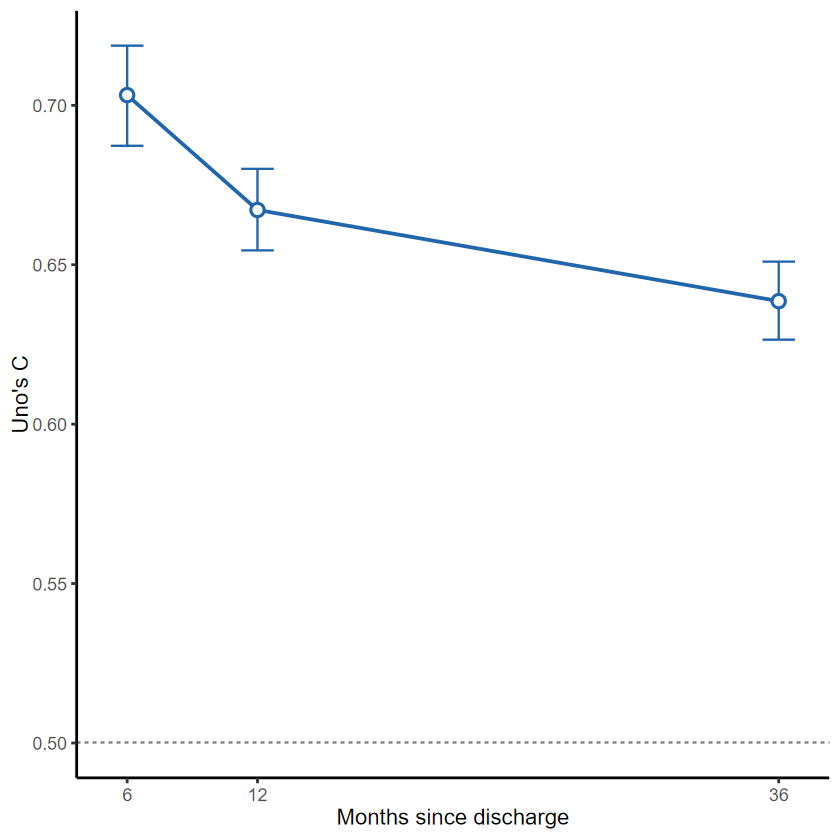

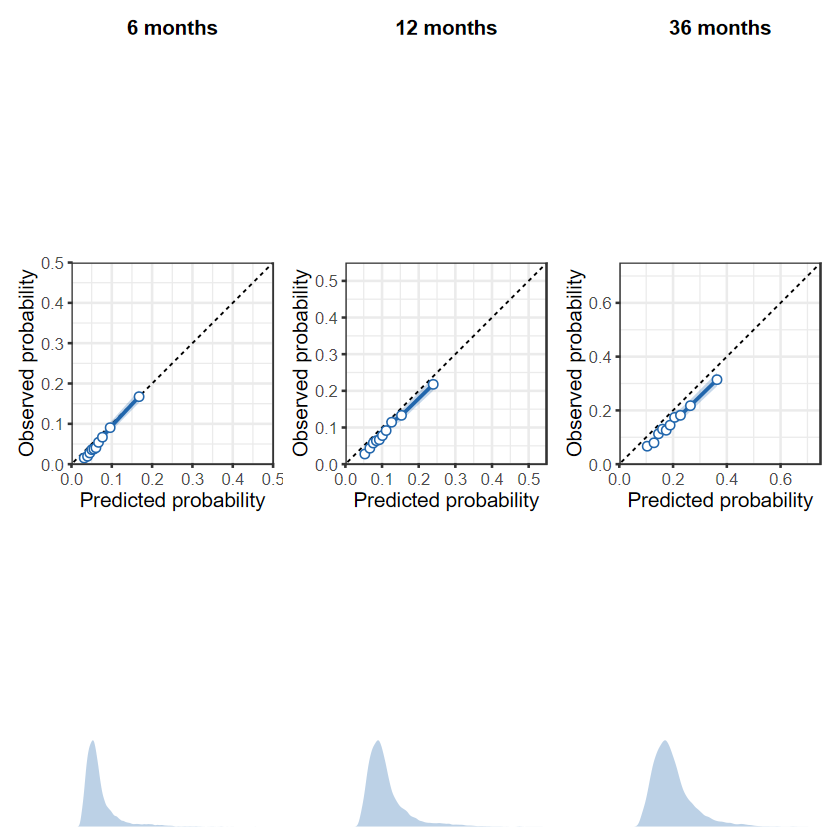

Elapsed: 0.016 minutes


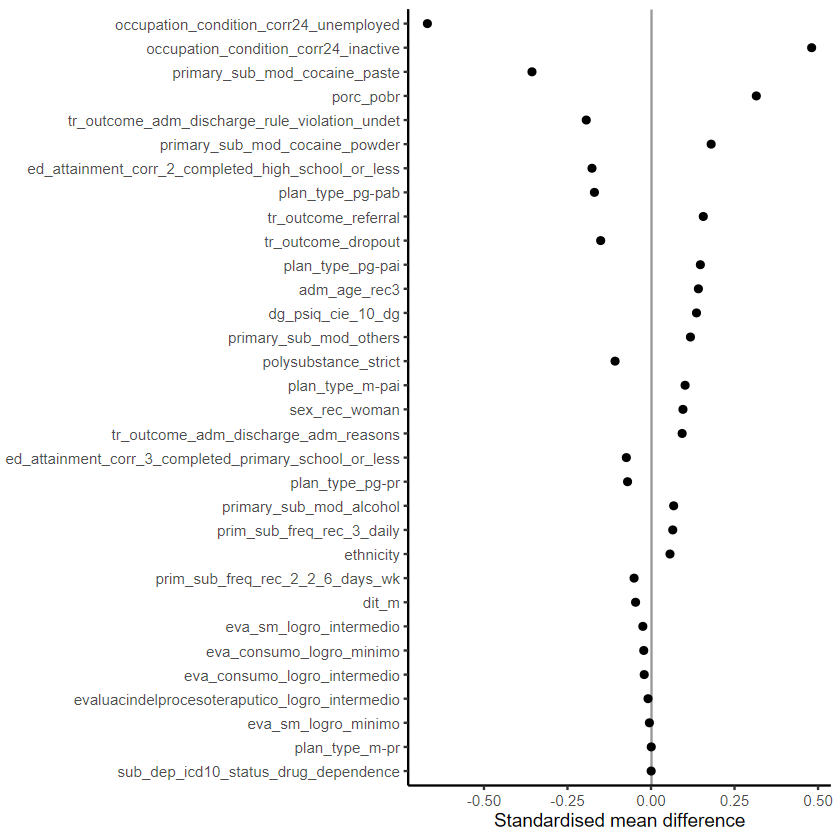

In [26]:
#| label: temporal-calibration-and-performance-figures
#| message: false
#| fig-width: 12
#| fig-height: 6
.t0 <- Sys.time()
# Display these intermediate figures in HTML; no manuscript figure identifier is assigned.
calibration_curves <- dplyr::bind_rows(lapply(seq_along(HORIZONS), function(j) calibration_curve_groups(predictions$time, predictions$event, predictions$risk$net[, match(HORIZONS[j], GRID)], HORIZONS[j])))
concordance_plot <- plot_concordance(data.frame(metric = paste0(HORIZONS, " months"), estimate = performance$uno_c, lower_95 = performance$uno_c_lower_95, upper_95 = performance$uno_c_upper_95))
print(concordance_plot)
calibration_panels <- lapply(seq_along(HORIZONS), function(j) create_calibration_panel(calibration_curves[calibration_curves$horizon_months == HORIZONS[j], ], predictions$risk$net[, match(HORIZONS[j], GRID)], HORIZONS[j]))
print(patchwork::wrap_plots(calibration_panels, nrow = 1))
print(ggplot2::ggplot(smd_summary, ggplot2::aes(Mean_SMD, stats::reorder(Variable, abs(Mean_SMD)))) + ggplot2::geom_vline(xintercept = 0, colour = "grey60") + ggplot2::geom_segment(ggplot2::aes(x = Minimum, xend = Maximum, yend = Variable), colour = "grey50") + ggplot2::geom_point() + ggplot2::labs(x = "Standardised mean difference", y = NULL) + ggplot2::theme_classic(base_size = 11))
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


In [27]:
#| label: temporal-manuscript-prior-new-comparison
#| message: false
.t0 <- Sys.time()
# Read the current Word table directly without changing the manuscript.
document <- xml2::read_xml(unz(source_path("manuscript"), "word/document.xml"))
ns <- xml2::xml_ns(document)
tables <- xml2::xml_find_all(document, ".//w:tbl", ns)
target <- tables[vapply(tables, function(tab) grepl("Temporal, first readmission", xml2::xml_text(tab), fixed = TRUE), logical(1L))]
stopifnot(length(target) == 1L)
rows <- lapply(xml2::xml_find_all(target[[1L]], "./w:tr", ns), function(row) xml2::xml_text(xml2::xml_find_all(row, "./w:tc", ns)))
start <- which(vapply(rows, function(row) identical(row[[1L]], "Temporal, first readmission"), logical(1L)))
stopifnot(length(start) == 1L)
word_rows <- rows[start + seq_along(HORIZONS) - 1L]
stopifnot(identical(vapply(word_rows, function(row) as.numeric(sub(" months", "", row[[2L]], fixed = TRUE)), numeric(1L)), HORIZONS))
metric_names <- c("uno_c", "ibs", "ici", "expected_to_observed")
comparison <- dplyr::bind_rows(lapply(seq_along(HORIZONS), function(j) dplyr::bind_rows(lapply(seq_along(metric_names), function(k) {
  metric <- metric_names[k]
  entry <- word_rows[[j]][[k + 2L]]
  values <- as.numeric(regmatches(entry, gregexpr("[0-9]+[.][0-9]+", entry))[[1L]])
  stopifnot(length(values) == 3L)
  fields <- paste0(metric, c("", "_lower_95", "_upper_95"))
  current <- as.numeric(unlist(performance[j, fields], use.names = FALSE))
  legacy <- as.numeric(unlist(historical$performance_external[j, fields], use.names = FALSE))
  digits <- if (metric == "expected_to_observed") 2L else 3L
  data.frame(Table = "Table 4: temporal readmission", Horizon_months = HORIZONS[j], Metric = metric, Component = c("estimate", "lower_95", "upper_95"), Manuscript = values, Historical_export = legacy, New_pipeline = current, Difference = current - values, Decimals = digits, Historical_export_disagrees = round(legacy, digits) != values, Classification = ifelse(round(current, digits) == values, "trivial", "substantial"), Word_entry = entry, row.names = NULL)
}))))
show_table(comparison, "Current Word versus clean temporal pipeline; classification uses published precision")
show_table(comparison[comparison$Historical_export_disagrees, ], "Historical export already differs from Word at its published precision")
cat("Substantial discrepancies await investigator review; no manuscript text or model choice was changed.\n")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Table,Horizon_months,Metric,Component,Manuscript,Historical_export,New_pipeline,Difference,Decimals,Historical_export_disagrees,Classification,Word_entry
Table 4: temporal readmission,6,uno_c,estimate,0.703,0.7029,0.7032,0.0002,3,FALSE,trivial,"0.703 (0.688, 0.718)"
Table 4: temporal readmission,6,uno_c,lower_95,0.688,0.6879,0.6873,-0.0007,3,FALSE,substantial,"0.703 (0.688, 0.718)"
Table 4: temporal readmission,6,uno_c,upper_95,0.718,0.7182,0.7187,0.0007,3,FALSE,substantial,"0.703 (0.688, 0.718)"
Table 4: temporal readmission,6,ibs,estimate,0.028,0.0277,0.0277,-0.0003,3,FALSE,trivial,"0.028 (0.026, 0.029)"
Table 4: temporal readmission,6,ibs,lower_95,0.026,0.0261,0.0262,0.0002,3,FALSE,trivial,"0.028 (0.026, 0.029)"
Table 4: temporal readmission,6,ibs,upper_95,0.029,0.0293,0.0292,0.0002,3,FALSE,trivial,"0.028 (0.026, 0.029)"
Table 4: temporal readmission,6,ici,estimate,0.014,0.0142,0.0143,0.0003,3,FALSE,trivial,"0.014 (0.012, 0.018)"
Table 4: temporal readmission,6,ici,lower_95,0.012,0.0119,0.0122,0.0002,3,FALSE,trivial,"0.014 (0.012, 0.018)"
Table 4: temporal readmission,6,ici,upper_95,0.018,0.0177,0.0176,-0.0004,3,FALSE,trivial,"0.014 (0.012, 0.018)"
Table 4: temporal readmission,6,expected_to_observed,estimate,1.250,1.2477,1.2466,-0.0034,2,FALSE,trivial,"1.25 (1.18, 1.32)"


Table,Horizon_months,Metric,Component,Manuscript,Historical_export,New_pipeline,Difference,Decimals,Historical_export_disagrees,Classification,Word_entry
Table 4: temporal readmission,12,uno_c,estimate,0.667,0.6665,0.6672,2e-04,3,TRUE,trivial,"0.667 (0.654, 0.680)"
Table 4: temporal readmission,12,ibs,estimate,0.046,0.0466,0.0465,5e-04,3,TRUE,trivial,"0.046 (0.045, 0.048)"
Table 4: temporal readmission,12,ibs,lower_95,0.045,0.0445,0.0446,-4e-04,3,TRUE,trivial,"0.046 (0.045, 0.048)"
Table 4: temporal readmission,12,ibs,upper_95,0.048,0.0485,0.0485,5e-04,3,TRUE,trivial,"0.046 (0.045, 0.048)"
Table 4: temporal readmission,12,ici,estimate,0.022,0.0215,0.0217,-3e-04,3,TRUE,trivial,"0.022 (0.017, 0.026)"
Table 4: temporal readmission,36,ibs,upper_95,0.090,0.0895,0.0892,-8e-04,3,TRUE,substantial,"0.087 (0.084, 0.090)"
Table 4: temporal readmission,36,ici,lower_95,0.037,0.0365,0.0368,-2e-04,3,TRUE,trivial,"0.043 (0.037, 0.050)"


Substantial discrepancies await investigator review; no manuscript text or model choice was changed.


Elapsed: 0.003 minutes


In [28]:
#| label: temporal-export-table4-and-provenance
#| message: false
.t0 <- Sys.time()
# Export direct Table-4 sources and reusable objects; keep intermediate figures in HTML.
write_table(performance, "Table4_temporal_performance")
write_table(comparison, "Table4_temporal_previous_new_comparison")
write_table(new_cohort_flow, "Table4_temporal_cohort_flow")
write_table(category_decision, "Table4_temporal_category_decision")
# Map every manuscript point and interval component to its producer and exported column.
traceability <- data.frame(Manuscript_item = comparison$Table, Outcome = "First readmission", Horizon_months = comparison$Horizon_months, Metric = comparison$Metric, Component = comparison$Component, Notebook = file.path(config$paths$notebooks, "10_readmission_temporal_int_val_21_24.ipynb"), Producer_cell = ifelse(comparison$Component == "estimate", "temporal-metric-functions-and-point-estimates", "temporal-bootstrap-original-1000"), Export_cell = "temporal-export-table4-and-provenance", Output_file = substring(output_file("tables", "Table4_temporal_performance"), nchar(root) + 2L), Output_column = paste0(comparison$Metric, ifelse(comparison$Component == "estimate", "", paste0("_", comparison$Component))), Manuscript_SHA256 = unname(input_hashes[["manuscript"]]), Status = ifelse(comparison$Classification == "substantial", "investigator_review_pending", "reproduced_at_published_precision"))
stopifnot(all(traceability$Output_column %in% names(performance)))
write_table(traceability, "Table4_temporal_traceability")
result <- list(performance = performance, traceability = traceability, comparison = comparison, category_decision = category_decision, cohort_flow = new_cohort_flow, support = support, supplementary_cif = cif_points, lp_diagnostics = lp_diagnostics, calibration_curves = calibration_curves, smd = smd_summary, provenance = list(input_sha256 = input_hashes, model_sha256 = model_sha256, imputation_signature = imputation_signature, analysis_signature = analysis_signature, settings = settings, seed = SEED, n_imputations = 5L, predictive_refits = 0L, observed_target = "1-KM; administrative censoring", primary_score = "net risk", calibration = "original exact-jackknife pseudo-values and LOESS", independence = c("Development-fitted frozen imputers", "Development-fitted frozen predictive models", "No temporal tuning, selection or recalibration", "Development imputations were completed before cross-validation; not fold-specific", "Censoring and calibration summaries estimated in evaluation cohort")))
invisible(cache_object("Table4_temporal_result", function() result))
note <- c("# Notebook 10: alcance y simplificaciones", "", "Se conservan las reglas originales de edad, ingreso, alta, traslado y seguimiento administrativo, con cierre el 20 de diciembre de 2024. La exclusion por egreso incompleto de 00 precede a la imputacion. Los cinco imputadores y modelos predictivos proceden de desarrollo; aqui solo se aplican. La decision sobre la categoria nueva queda registrada, sin convertirla silenciosamente en referencia.", "", "Se mantienen las 1.000 replicas bootstrap. En cada replica se estima una vez la curva de censura y se reutiliza en todos los tiempos; un control sintetico verifica igualdad con el codigo original. Se preservan los limites 0,01 para IBS principal y 0,05 para habilidad complementaria. En ambos casos la censura se estima nuevamente dentro de cada replica.", "", "Las comparaciones complementarias CIF y de predictor lineal se muestran sin repetir intervalos bootstrap. La evaluacion redundante del holdout se cubre en 09. Las simulaciones opcionales de precision y los reajustes predictivos del riesgo basal no se ejecutan porque no alimentan la Tabla 4 actual. Se pueden restaurar sus bloques originales tras acordar ese alcance. Figuras y diferencias descriptivas entre cohortes quedan en HTML: no se verifico que correspondan a una figura numerada del manuscrito.", "", "Independencia: los predictores temporales se completan con imputadores congelados de desarrollo y las predicciones usan coeficientes y riesgos basales aprendidos en desarrollo. Los desenlaces temporales solo se usan para evaluar, estimar censura y describir calibracion. Las imputaciones de desarrollo se completaron antes de la validacion cruzada: no debe afirmarse independencia por fold de todo el descubrimiento previo. La evaluacion temporal historica usaba casos completos; las diferencias no se atribuyen solo a corregir la fuga de informacion. Sin fechas individuales de defuncion posteriores a 2020, el riesgo observado temporal no es una CIF de Aalen-Johansen.")
note_path <- output_file("docs", "10_temporal_scope_simplifications", "md")
writeLines(note, note_path, useBytes = TRUE)
written <- unique(c(written, note_path))
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.009 minutes


## Session info

In [29]:
#| label: temporal-session-info
#| message: false
.t0 <- Sys.time()
# Persist the actual runtime and resource summary for this execution.
print(sessionInfo())
session_path <- output_file("docs", "10_temporal_sessionInfo", "txt")
writeLines(utils::capture.output(sessionInfo()), session_path)
written <- unique(c(written, session_path))
show_table(data.frame(Elapsed_minutes = as.numeric(difftime(Sys.time(), run_started, units = "mins")), Process_RSS_GiB = as.numeric(ps::ps_memory_info()[["rss"]]) / 1024^3, Available_RAM_GiB = as.numeric(ps::ps_system_memory()[["avail"]]) / 1024^3, Threads = threads, Bootstrap_workers_maximum = settings$workers), "Temporal evaluation resources")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


R version 4.4.1 (2024-06-14 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default


locale:
[1] LC_COLLATE=C                        LC_CTYPE=English_United States.utf8
[3] LC_MONETARY=C                       LC_NUMERIC=C                       
[5] LC_TIME=C                          

time zone: America/Santiago
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
  [1] tidyselect_1.2.1          nanoparquet_0.4.2        
  [3] IRdisplay_1.1             dplyr_1.1.4              
  [5] farver_2.1.2              fastmap_1.2.0            
  [7] TH.data_1.1-3             janitor_2.2.1            
  [9] digest_0.6.37             rpart_4.1.23             
 [11] timechange_0.3.0          lifecycle_1.0.5          
 [13] cluster_2.1.8.1           Cairo_1.6-2              
 [15] survival_3.6-4            magrittr_2.0.3           
 

Elapsed_minutes,Process_RSS_GiB,Available_RAM_GiB,Threads,Bootstrap_workers_maximum
12.5988,1.2052,58.9796,1,6


Elapsed: 0.010 minutes


## Written files

In [30]:
#| label: temporal-written-files-and-status
#| message: false
.t0 <- Sys.time()
# List every new or reused output artifact using project-relative paths and sizes.
all_artifacts <- unique(c(written, reused))
manifest <- data.frame(Path = substring(all_artifacts, nchar(root) + 2L), Bytes = as.numeric(file.info(all_artifacts)$size), Status = ifelse(all_artifacts %in% written, "written", "reused"))
stopifnot(all(file.exists(all_artifacts)), all(startsWith(normalizePath(all_artifacts, winslash = "/"), paste0(root, "/"))))
show_table(manifest[startsWith(manifest$Path, "outputs/"), ], "Files written or reused in outputs/")
show_table(manifest[startsWith(manifest$Path, "docs/"), ], "Execution documentation")
cat(sprintf("Elapsed: %.3f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Path,Bytes,Status
outputs/objects/temporal10_completed_encoded_imp1_2026-10-10_4b5d87a16e05.rds,19123214,written
outputs/objects/temporal10_completed_encoded_imp2_2026-10-10_4b5d87a16e05.rds,19123214,written
outputs/objects/temporal10_completed_encoded_imp3_2026-10-10_4b5d87a16e05.rds,19123214,written
outputs/objects/temporal10_completed_encoded_imp4_2026-10-10_4b5d87a16e05.rds,19123214,written
outputs/objects/temporal10_completed_encoded_imp5_2026-10-10_4b5d87a16e05.rds,19123214,written
outputs/objects/Table4_temporal_frozen_predictions_2026-10-10_62965812c82b.rds,85876028,written
outputs/objects/Table4_temporal_point_metrics_2026-10-10_62965812c82b.rds,1067,written
outputs/objects/temporal10_cif_point_metrics_2026-10-10_62965812c82b.rds,1668,written
outputs/objects/Table4_temporal_bootstrap_batch01_2026-10-10_62965812c82b.rds,44342,written
outputs/objects/Table4_temporal_bootstrap_batch02_2026-10-10_62965812c82b.rds,44342,written


Path,Bytes,Status
docs/10_temporal_scope_simplifications_2026-10-10_62965812c82b.md,1980,written
docs/10_temporal_sessionInfo_2026-10-10_62965812c82b.txt,3596,written


Elapsed: 0.001 minutes
